# EchoQuality — Post-Processing & Analysis Pipeline

This notebook aggregates video-level EchoQuality predictions to study-level labels, evaluates AI model performance across quality strata, and generates results files, tables and figures.

---

## 1 · Dataset Load

Load all required input files and build the foundational data structures used throughout the pipeline.

### Input Files

| File | Content |
|------|---------|
| `inference_predictions_*.csv` | Video-level EchoQuality logits (one row per video) |
| `view_identification_*.csv` | Anatomical view label per video |
| `panecho_*.csv` | PanEcho cardiac measurement & disease predictions |
| `echoprime_*.csv` | EchoPrime cardiac measurement & disease predictions |
| `ground_truth_*.csv` | Clinical reference measurements & diagnoses |
| `patient_demographics_*.csv` | Age, sex, BMI, BSA per patient |

### Key Processing Steps

1. **Patient ID extraction** — derived from the video file path (second-to-last directory component)
2. **Video–view join** — quality predictions merged with view labels on `path`
3. **Quality label assignment** — raw logits → softmax → argmax → `{0: bad, 1: normal, 2: good}`
4. **Study-level aggregation** — video-level labels voted up to study level using a two-stage rule:
   - If `bad` count > `normal + good` combined → study is **bad**
   - Otherwise: `good` beats `normal`; ties go to **good**
   - Else: **normal**
5. **View-aware study quality** — the best-quality per anatomical view is selected first, then the same voting rule is applied across views *(canonical quality used downstream)*

In [1]:
import ast
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import softmax
from sklearn.metrics import mean_absolute_error, precision_score, recall_score, r2_score, roc_auc_score

# turn off warnings
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

# write cohort name
cohort_name = 'output'
output_dir = Path('results') / 'echoQual_inference' / cohort_name
output_dir.mkdir(parents=True, exist_ok=True)

panecho = pd.read_csv(r'results\echoQual_inference\panecho_EXAMPLE.csv', index_col=0)
echoprime = pd.read_csv(r'results\echoQual_inference\echoprime_EXAMPLE.csv', index_col=0)
ground_truth = pd.read_csv(r'results\echoQual_inference\ground_truth_EXAMPLE.csv', index_col=0)
view_ident = pd.read_csv(r'results\echoQual_inference\view_identification_EXAMPLE.csv', index_col=0)
demographics = pd.read_csv(r'results\echoQual_inference\patient_demographics_EXAMPLE.csv', index_col=0)
quality_pred = pd.read_csv(r'results\echoQual_inference\inference_predictions_EXAMPLE_calidad_1.csv', index_col=0)

In [2]:
def extract_patient_id_from_path(path):
    return str(path).replace('\\', '/').split('/')[-2]

video_df = quality_pred.merge(view_ident, on='path', how='left')
video_df['patient_id'] = video_df['path'].apply(extract_patient_id_from_path)
video_df.head()


,path,fname,quality,view,patient_id
0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[-1.033998966217041, 0.6184679269790649, 0.026...",A3C,ECHO_1
1,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[-1.704994559288025, 0.7010875344276428, 0.911...",A2C,ECHO_1
2,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[0.394212543964386, 0.6401153802871704, -1.412...",A4C,ECHO_1
3,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[1.4762012958526611, 0.4506734311580658, -2.34...",A3C,ECHO_1
4,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[1.9497514963150024, -0.05845397338271141, -2....",A2C,ECHO_1


In [3]:
# Remove view == 'other'
quality_videos = video_df[video_df['view'].isin(['A2C', 'A3C', 'A4C', 'A5C', 'PSAX_AO', 'PSAX_PM', 'PSAX_MV', 'PLAX'])].copy()

# Process quality labels: softmax + argmax (0: bad, 1: normal, 2: good)
def get_quality_label(quality_val):
    """Get quality label from softmax + argmax"""
    # Parse quality if it's a string representation of a list
    if isinstance(quality_val, str):
        quality_val = ast.literal_eval(quality_val)
    
    quality_array = np.array(quality_val, dtype=float)
    probs = softmax(quality_array)
    label = np.argmax(probs)
    return label

quality_videos['quality_label'] = quality_videos['quality'].apply(get_quality_label)

# Collapse PSAX subviews for view-level voting only
quality_videos['view_vote'] = quality_videos['view'].replace({
    'PSAX_AO': 'PSAX',
    'PSAX_PM': 'PSAX',
    'PSAX_MV': 'PSAX',
})

# Voting at patient level
def vote_quality(group):
    """
    Vote quality at patient level:
    - bad vs (normal+good): if more bad -> bad, else continue
    - normal vs good: if more normal -> normal, else -> good
    """
    labels = group['quality_label'].values
    
    # Count each label
    bad_count = np.sum(labels == 0)
    normal_count = np.sum(labels == 1)
    good_count = np.sum(labels == 2)
    
    # First level: bad vs (normal+good)
    if bad_count > (normal_count + good_count):
        return 0  # bad
    
    # If normal+good is equal or more, distinguish between normal and good
    if normal_count > good_count:
        return 1  # normal
    else:  # good_count >= normal_count
        return 2  # good

quality_patient = quality_videos.groupby('patient_id').apply(vote_quality).reset_index()
quality_patient.columns = ['patient_id', 'quality_label']

# Map numeric labels to quality names
quality_map = {0: 'bad', 1: 'normal', 2: 'good'}
quality_patient['quality_study'] = quality_patient['quality_label'].map(quality_map)


# Voting at patient level
def vote_quality(group):
    """
    Vote quality at patient level:
    - bad vs (normal+good): if more bad -> bad, else continue
    - normal vs good: if more normal -> normal, else -> good
    """
    labels = group['quality_label'].values
    
    # Count each label
    bad_count = np.sum(labels == 0)
    normal_count = np.sum(labels == 1)
    good_count = np.sum(labels == 2)
    
    # First level: bad vs (normal+good)
    if bad_count > (normal_count + good_count):
        return 0  # bad
    
    # If normal+good is equal or more, distinguish between normal and good
    if normal_count > good_count:
        return 1  # normal
    else:  # good_count >= normal_count
        return 2  # good

quality_patient = quality_videos.groupby('patient_id').apply(vote_quality).reset_index()
quality_patient.columns = ['patient_id', 'quality_label']

# Best quality per distinct view, then vote across views using the same study criteria
quality_view_max = (
    quality_videos.groupby(['patient_id', 'view_vote'])['quality_label']
    .max()
    .reset_index()
)
quality_patient_view = quality_view_max.groupby('patient_id').apply(vote_quality).reset_index()
quality_patient_view.columns = ['patient_id', 'quality_label_view']
quality_patient = quality_patient.merge(quality_patient_view, on='patient_id', how='left')

# Map numeric labels to quality names
quality_map = {0: 'bad', 1: 'normal', 2: 'good'}
quality_patient['quality_study'] = quality_patient['quality_label'].map(quality_map)
quality_patient['quality_study_view'] = quality_patient['quality_label_view'].map(quality_map)

# Use the view-based study quality as the canonical study-level quality downstream
quality_patient['quality_label'] = quality_patient['quality_label_view']
quality_patient['quality_study'] = quality_patient['quality_study_view']

quality_patient.head()

,patient_id,quality_label,quality_label_view,quality_study,quality_study_view
0,ECHO_1,2,2,good,good
1,ECHO_10,0,0,bad,bad
2,ECHO_11,1,1,normal,normal
3,ECHO_12,2,2,good,good
4,ECHO_13,1,1,normal,normal


---

## 2 · EchoQuality — Study-Level Distribution

Characterize how EchoQuality labels distribute across the cohort and test whether quality is associated with patient demographics or temporal acquisition trends.

### Analyses

| Analysis | Variables | Statistical Test |
|----------|-----------|-----------------|
| Quality distribution | bad / normal / good counts | — |
| Temporal trends | Study acquisition year | — |
| Sex differences | Male / Female | χ² |
| Age distribution | Age groups / continuous | Kruskal–Wallis |
| BMI distribution | BMI groups / continuous | Kruskal–Wallis |


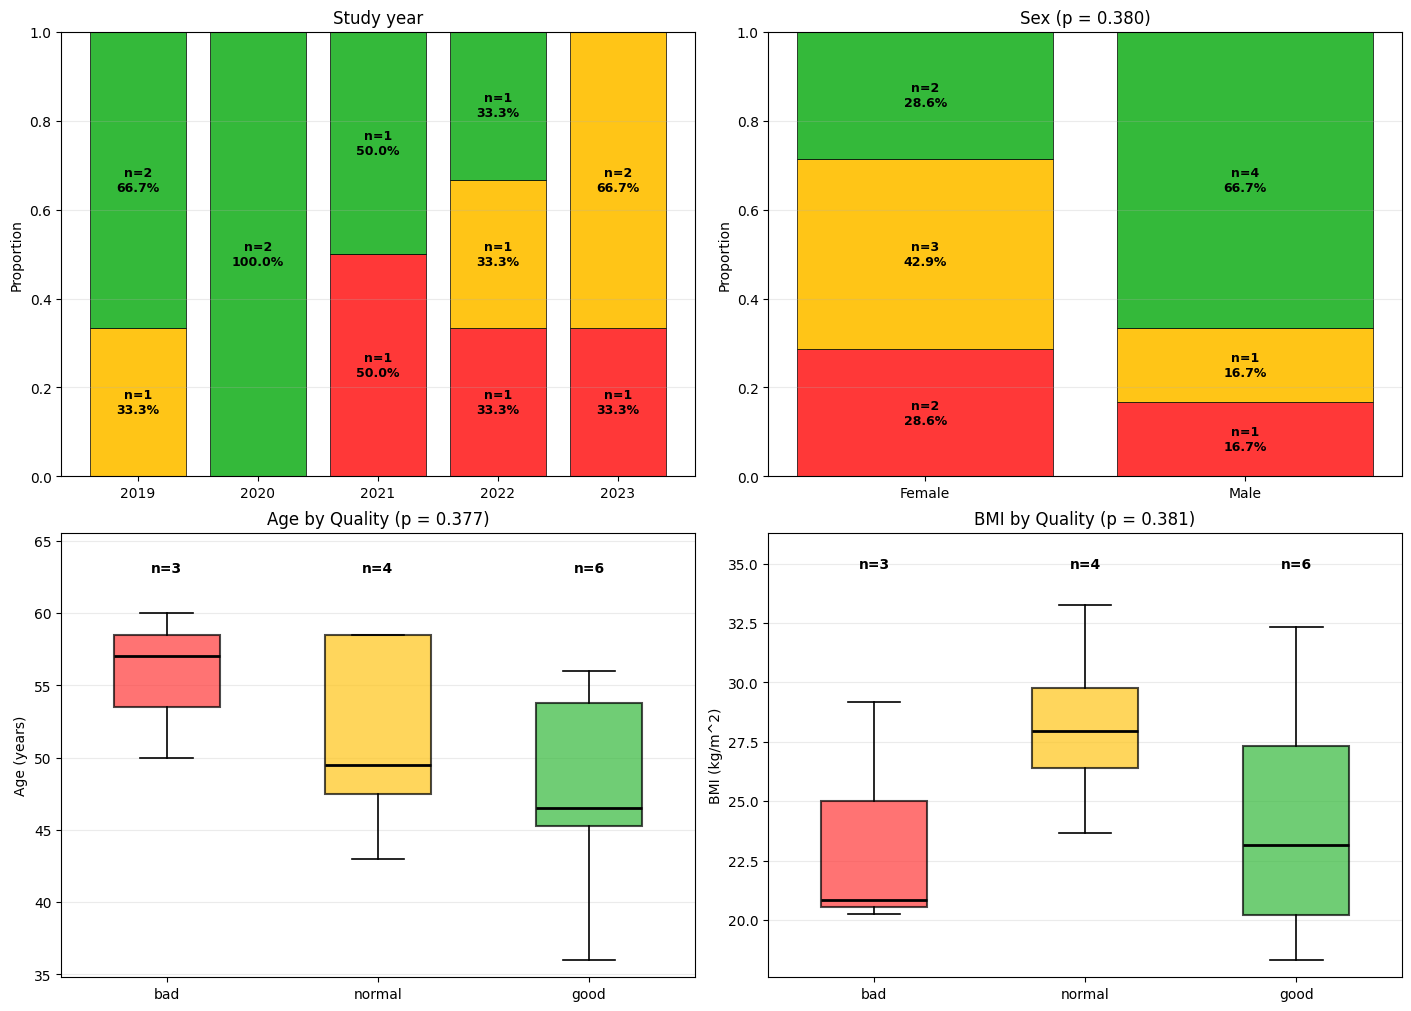

In [4]:
palette = {'bad': '#ff3838', 'normal': '#ffc517', 'good': '#34b93a'}
quality_col = 'calidad_label'
from scipy import stats

quality_order = ['bad', 'normal', 'good']
colors = palette

df = demographics.merge(
    quality_patient[['patient_id', 'quality_study']],
    on='patient_id',
    how='inner'
).rename(columns={'quality_study': 'calidad_label'})

def format_p_value(p_value):
    if pd.isna(p_value):
        return 'p = NA'
    if p_value < 0.001:
        return 'p < 0.001'
    return f'p = {p_value:.3f}'

def stacked_quality_bars(ax, df_in, group_col, title, group_order=None, rotate_xticks=0):
    d = df_in[[group_col, quality_col, 'patient_id']].dropna().copy()
    d[group_col] = d[group_col].astype(str)

    counts = pd.crosstab(d[group_col], d[quality_col])
    counts = counts.reindex(columns=quality_order, fill_value=0)

    if group_order is None:
        counts = counts.sort_index()
    else:
        counts = counts.reindex([str(x) for x in group_order]).dropna(how='all').fillna(0)

    props = counts.div(counts.sum(axis=1), axis=0).fillna(0)

    bottom = np.zeros(len(props))
    x = np.arange(len(props))
    for q in quality_order:
        vals = props[q].to_numpy()
        ax.bar(x, vals, bottom=bottom, color=colors[q], label=q, edgecolor='black', linewidth=0.5)

        for i, val in enumerate(vals):
            n_label = int(counts.iloc[i][q])
            if n_label > 0 and val > 0:
                ax.text(
                    x[i],
                    bottom[i] + val / 2,
                    f'n={n_label}\n{val * 100:.1f}%',
                    ha='center',
                    va='center',
                    fontsize=9,
                    fontweight='bold'
                )

        bottom += vals

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(props.index.tolist(), rotation=rotate_xticks, ha='right' if rotate_xticks else 'center')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Proportion')
    ax.grid(axis='y', alpha=0.25)

def draw_box(ax, data, counts, title, ylabel, quality_order, palette):
    valid_pairs = [(q, arr) for q, arr in zip(quality_order, data) if len(arr) > 0]
    if not valid_pairs:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.set_axis_off()
        return
    plot_order = [q for q, _ in valid_pairs]
    plot_data = [arr for _, arr in valid_pairs]

    box = ax.boxplot(
        plot_data,
        tick_labels=plot_order,
        patch_artist=True,
        showfliers=False,
        widths=0.5,
        medianprops=dict(color='black', linewidth=2),
        boxprops=dict(edgecolor='black', linewidth=1.5),
        whiskerprops=dict(color='black', linewidth=1.2),
        capprops=dict(color='black', linewidth=1.2)
    )

    for patch, q in zip(box['boxes'], plot_order):
        patch.set_facecolor(palette[q])
        patch.set_alpha(0.7)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.25)
    y0, y1 = ax.get_ylim()
    y_text = y1 - 0.06 * (y1 - y0)
    for i, q in enumerate(plot_order, start=1):
        ax.text(i, y_text + 0.05*y_text, f'n={counts[q]}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylim(top=y_text + 0.1*y_text)
# -------- prepare df_plot --------
df_plot = df.copy()

df_plot['year'] = pd.to_numeric(df_plot['year_of_study'], errors='coerce').astype('Int64')
df_plot['sex'] = df_plot['sex'].astype(str).str.strip()
df_plot['sex'] = df_plot['sex'].where(df_plot['sex'].isin(['Male', 'Female']), np.nan)

df_plot['age'] = pd.to_numeric(df_plot['age'], errors='coerce')
df_plot['imc'] = pd.to_numeric(df_plot['imc'], errors='coerce')

sex_table = pd.crosstab(df_plot.dropna(subset=['sex'])['sex'], df_plot.dropna(subset=['sex'])[quality_col])
if sex_table.shape[0] > 1 and sex_table.shape[1] > 1:
    _, sex_p_value, _, _ = stats.chi2_contingency(sex_table)
else:
    sex_p_value = np.nan

age_groups = [
    df_plot.loc[df_plot[quality_col] == quality, 'age'].dropna().to_numpy(dtype=float)
    for quality in quality_order
]
age_groups = [group for group in age_groups if len(group) > 0]
if len(age_groups) >= 2:
    _, age_p_value = stats.kruskal(*age_groups)
else:
    age_p_value = np.nan

bmi_groups = [
    df_plot.loc[df_plot[quality_col] == quality, 'imc'].dropna().to_numpy(dtype=float)
    for quality in quality_order
]
bmi_groups = [group for group in bmi_groups if len(group) > 0]
if len(bmi_groups) >= 2:
    _, bmi_p_value = stats.kruskal(*bmi_groups)
else:
    bmi_p_value = np.nan

demographic_pvalues_df = pd.DataFrame([
    {'variable': 'sex', 'test': 'chi_square', 'p_value': sex_p_value},
    {'variable': 'age', 'test': 'kruskal', 'p_value': age_p_value},
    {'variable': 'bmi', 'test': 'kruskal', 'p_value': bmi_p_value},
])

study_level_demographics_by_quality_df = df_plot[
    ['patient_id', quality_col, 'year_of_study', 'sex', 'age', 'imc']
].rename(columns={
    quality_col: 'quality',
    'year_of_study': 'study_year',
    'imc': 'bmi'
})

edad_data, imc_data = [], []
edad_counts, imc_counts = {}, {}
for q in quality_order:
    dqq = df_plot[df_plot[quality_col] == q]

    edad_counts[q] = dqq.loc[dqq['age'].notna(), 'patient_id'].nunique()
    edad_vals = dqq['age'].to_numpy(float)
    edad_vals = edad_vals[~np.isnan(edad_vals)]
    edad_data.append(edad_vals)

    imc_counts[q] = dqq.loc[dqq['imc'].notna(), 'patient_id'].nunique()
    imc_vals = dqq['imc'].to_numpy(float)
    imc_vals = imc_vals[~np.isnan(imc_vals)]
    imc_data.append(imc_vals)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

years = sorted(df_plot['year'].dropna().unique().astype(int).tolist())
rotate = 45 if len(years) > 8 else 0
stacked_quality_bars(axes[0, 0], df_plot, 'year', 'Study year', group_order=years, rotate_xticks=rotate)
stacked_quality_bars(axes[0, 1], df_plot, 'sex', f'Sex ({format_p_value(sex_p_value)})')

draw_box(
    axes[1, 0], edad_data, edad_counts,
    title=f'Age by Quality ({format_p_value(age_p_value)})',
    ylabel='Age (years)',
    quality_order=quality_order,
    palette=palette
)

draw_box(
    axes[1, 1], imc_data, imc_counts,
    title=f'BMI by Quality ({format_p_value(bmi_p_value)})',
    ylabel='BMI (kg/m^2)',
    quality_order=quality_order,
    palette=palette
)
plt.savefig(output_dir / 'cohort_demographics_by_quality.png', dpi=300)

plt.show()


---

## 3 · EchoQuality vs. AI Model Performance

Quantify how study-level EchoQuality predicts the accuracy of downstream AI predictions. Analyses are stratified by quality group (`bad`, `normal`, `good`) for both continuous measurements and binary disease classifications.

### Models Under Evaluation

| Model | Type | Outputs |
|-------|------|---------|
| **PanEcho** | Multi-view echocardiography foundational model | Continuous measurements + disease probabilities |
| **EchoPrime** | Echocardiography foundational model | Ejection Fraction + disease probabilities |

### 3.1 · PanEcho — View-Aware Study-Level Aggregation

PanEcho generates predictions at the **video level**. Before computing study-level performance, predictions are aggregated across videos using an anatomically informed strategy rather than a naive mean over all available clips.

**Aggregation logic:**

1. Each cardiac task is mapped to the echocardiographic views that visualize the relevant cardiac structure
   *(e.g., LVEF → apical views, parasternal long-axis, parasternal short-axis on papillary muscle)*
2. For a given study, only videos from anatomically relevant views are included in the mean for that task
3. Videos from unrelated views are excluded from that task's aggregation

In [5]:
panecho['patient_id'] = panecho['path'].apply(extract_patient_id_from_path)

if 'view' not in panecho.columns:
    panecho = panecho.merge(
        view_ident[['path', 'view']].drop_duplicates(subset=['path']),
        on='path',
        how='left'
    )
panecho['view'] = panecho['view'].astype(str).str.strip().str.upper()

def parse_array_string(value):
    """Convert an array-like string or numeric value into a list of floats."""
    if pd.isna(value) or value == '' or value is None:
        return None
    
    value_str = str(value).strip()
    
    # Handle strings that represent arrays enclosed in brackets.
    if value_str.startswith('[') and value_str.endswith(']'):
        try:
            # Remove brackets and split on commas/whitespace.
            value_str = value_str[1:-1].strip()
            # Convert values, including scientific notation.
            parts = value_str.replace(',', ' ').split()
            return [float(p) for p in parts if p]
        except (ValueError, IndexError):
            return None
    
    # Handle plain numeric values.
    try:
        return [float(value_str)]
    except ValueError:
        return None
    
def mean_of_list_v2(series_of_values):
    """
    Compute the element-wise mean across multiple lists for one patient_id.
    Example: [[a,b,c], [e,f,g]] -> [(a+e)/2, (b+f)/2, (c+g)/2]
    Return a list with the mean at each position.
    """
    all_arrays = []
    
    for value in series_of_values:
        parsed = parse_array_string(value)
        if parsed is not None:
            all_arrays.append(parsed)
    
    if not all_arrays:
        return np.nan
    
    # If there is only one array, return it unchanged.
    if len(all_arrays) == 1:
        return all_arrays[0]
    
    # Compute the element-wise mean by aligning values by position.
    max_len = max(len(arr) for arr in all_arrays)
    
    # Pad shorter arrays with NaN values.
    arrays_padded = []
    for arr in all_arrays:
        if len(arr) < max_len:
            arr = arr + [np.nan] * (max_len - len(arr))
        arrays_padded.append(arr)
    
    # Compute the mean for each position.
    element_means = np.nanmean(np.array(arrays_padded), axis=0)
    
    # Return the result as a list.
    return element_means.tolist()

metric_groups = {
    'AORoot': ['A3C', 'A5C', 'PSAX_AO', 'PLAX'],
    'AVPkVel(m|s)': ['A3C', 'A5C', 'PSAX_AO', 'PLAX'],
    'RVSVel': ['A4C', 'A5C', 'PSAX_AO'],
    'TAPSE': ['A4C', 'A5C', 'PSAX_AO'],
    'TVPkGrad': ['A4C', 'A5C'],
    'E|EAvg': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX'],
    'EF': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'LVEDV': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'LVESV': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'LVIDd': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'LAIDs2D': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'LAVol': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
    'IVSd': ['A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'],
}

ef_views = metric_groups['EF']
for metric_name in ['LVSV', 'LVPWd', 'LVIDs', 'LVIDd', 'LVOTDiam']:
    metric_groups[metric_name] = ef_views

rv_views = metric_groups['RVSVel']
for metric_name in ['RVSP', 'RVIDd']:
    metric_groups[metric_name] = rv_views

metric_groups['RADimensionM-L(cm)'] = ['A4C', 'A5C']

structure_views = {
    'AV': {'PSAX_AO', 'PLAX', 'A3C', 'A5C'},
    'MV': {'A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'},
    'TV': {'A4C', 'A5C'},
    'LV': {'A2C', 'A3C', 'A4C', 'A5C', 'PLAX', 'PSAX_PM'},
}
tasks_binary = [
    {'source_col': 'AVStructure', 'output_col': 'AVStructure', 'structure': 'AV'},
    {'source_col': 'MVStenosis', 'output_col': 'MVStenosis', 'structure': 'MV'},
    {'source_col': 'LVWallThickness-increased-any', 'output_col': 'LVWallThickness-increased-any', 'structure': 'MV'},
    {'source_col': 'pericardial-effusion', 'output_col': 'PericardialEffusion', 'structure': 'LV'},
]
tasks_multiclass = [
    {'source_col': 'AVStenosis', 'output_col': 'AVStenosis', 'structure': 'AV'},
    {'source_col': 'AVRegurg', 'output_col': 'AVRegurg', 'structure': 'AV'},
    {'source_col': 'MVRegurgitation', 'output_col': 'MVRegurgitation', 'structure': 'MV'},
    {'source_col': 'TVRegurgitation', 'output_col': 'TVRegurgitation', 'structure': 'TV'},
]

panecho_study = pd.DataFrame(index=pd.Index(panecho['patient_id'].dropna().unique(), name='patient_id'))

for metric_name, views_loop in metric_groups.items():
    if metric_name not in panecho.columns:
        continue
    panecho[metric_name] = pd.to_numeric(panecho[metric_name], errors='coerce')
    metric_df = panecho.loc[
        panecho['view'].isin(views_loop),
        ['patient_id', metric_name]
    ].dropna(subset=['patient_id'])
    panecho_study[metric_name] = metric_df.groupby('patient_id')[metric_name].mean()

for task in tasks_binary:
    source_col = task['source_col']
    if source_col not in panecho.columns:
        continue
    panecho[source_col] = pd.to_numeric(panecho[source_col], errors='coerce')
    task_df = panecho.loc[
        panecho['view'].isin(structure_views[task['structure']]),
        ['patient_id', source_col]
    ].dropna(subset=['patient_id'])
    panecho_study[task['output_col']] = task_df.groupby('patient_id')[source_col].mean()

for task in tasks_multiclass:
    source_col = task['source_col']
    if source_col not in panecho.columns:
        continue
    task_df = panecho.loc[
        panecho['view'].isin(structure_views[task['structure']]),
        ['patient_id', source_col]
    ].dropna(subset=['patient_id'])
    panecho_study[task['output_col']] = task_df.groupby('patient_id')[source_col].apply(mean_of_list_v2)

if 'PericardialEffusion' in panecho_study.columns:
    panecho_study['pericardial-effusion'] = panecho_study['PericardialEffusion']

panecho_study = panecho_study.reset_index()

panecho_study.head()

,patient_id,AORoot,AVPkVel(m|s),RVSVel,TAPSE,TVPkGrad,E|EAvg,EF,LVEDV,LVESV,...,RADimensionM-L(cm),AVStructure,MVStenosis,LVWallThickness-increased-any,PericardialEffusion,AVStenosis,AVRegurg,MVRegurgitation,TVRegurgitation,pericardial-effusion
0,ECHO_1,3.310570,2.012386,13.533027,2.049851,30.173164,12.608828,55.102927,113.434834,53.936055,...,3.836046,0.003001,0.097185,0.416437,0.030672,"[0.26187083333846156, 0.6461701676923076, 0.09...","[0.22398270307692308, 0.058541526153846155, 0....","[0.3298945483333334, 0.20634170699999999, 0.46...","[0.34466021692307697, 0.2064667238461539, 0.44...",0.030672
1,ECHO_2,3.394962,1.782159,12.360140,1.954478,28.299220,12.127927,49.510414,129.221696,66.313567,...,4.198577,0.004625,0.055382,0.474111,0.067771,"[0.13949242333333334, 0.7865114066666666, 0.07...","[0.21602646499999997, 0.07207351666666666, 0.7...","[0.3728815515, 0.19426360850000002, 0.432854835]","[0.37354674874999994, 0.24751606875, 0.3789372...",0.067771
2,ECHO_3,3.556740,1.524133,NaN,NaN,NaN,12.786212,41.493916,145.684890,84.966797,...,NaN,0.000622,0.025998,0.355305,0.024049,"[0.06549437, 0.9238036, 0.01070197]","[0.21975105, 0.06864445, 0.7116045]","[0.43520592, 0.431563725, 0.13323037]",NaN,0.024049
3,ECHO_4,3.256613,1.570121,12.781664,1.929410,28.108126,11.399753,47.966983,123.129535,64.125372,...,3.882733,0.011900,0.040468,0.411876,0.102641,"[0.17026235666666667, 0.7852190533333333, 0.04...","[0.20018971333333332, 0.04982291666666666, 0.7...","[0.3651570544444444, 0.2734004488888889, 0.361...","[0.3086408133333333, 0.25802178833333334, 0.43...",0.102641
4,ECHO_5,NaN,NaN,13.354128,1.954351,28.999193,14.619613,57.110752,99.817283,43.827321,...,4.324733,NaN,0.144158,0.628906,0.055283,NaN,NaN,"[0.45552275499999995, 0.2326289225, 0.31184832...","[0.2641596425, 0.3926019925, 0.34323838]",0.055283


In [6]:
panecho

,path,pericardial-effusion,EF,GLS,LVEDV,LVESV,LVSV,LVSize,LVWallThickness-increased-any,LVWallThickness-increased-modsev,...,AVRegurg,LVOT20mmHg,MVStenosis,MVRegurgitation,TVRegurgitation,TVPkGrad,RAP-8-or-higher,AORoot,patient_id,view
0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,0.047543,56.670440,15.566360,126.186040,56.425610,69.125496,[0.06824983 0.04189356 0.88985664],0.584131,0.175861,...,[0.15583141 0.04801922 0.7961494 ],0.009008,0.025808,[0.3362964 0.16694306 0.49676058],[0.29763433 0.16687696 0.5354887 ],28.055828,0.430333,3.405603,ECHO_1,A3C
1,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,0.008599,61.279488,19.564850,118.621445,45.622437,72.826935,[0.03842691 0.00525899 0.956314 ],0.064454,0.004998,...,[0.04063476 0.00802272 0.9513425 ],0.000435,0.001320,[0.1305855 0.01151135 0.8579032 ],[0.21931767 0.01759543 0.76308686],17.920464,0.104471,3.232805,ECHO_1,A2C
2,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,0.024906,68.636170,13.505386,102.041670,42.358177,61.462452,[2.0636080e-03 3.1129183e-04 9.9762505e-01],0.679592,0.122358,...,[0.24039899 0.08569139 0.6739096 ],0.018083,0.852695,[0.2016133 0.7377014 0.06068525],[0.29325053 0.2400942 0.46665525],30.088268,0.019233,2.779400,ECHO_1,A4C
3,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,0.025641,48.604317,13.837538,152.736220,81.227780,71.219730,[0.09460894 0.04135747 0.8640336 ],0.709537,0.092558,...,[0.13937497 0.01280039 0.8478246 ],0.000159,0.016229,[0.14816847 0.02516874 0.82666284],[0.19621393 0.01311854 0.79066753],26.382008,0.063775,3.577386,ECHO_1,A3C
4,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,0.120842,55.492634,11.171932,104.888170,50.803326,54.104267,[0.01754493 0.00328401 0.9791711 ],0.855303,0.442615,...,[0.35872218 0.13190478 0.509373 ],0.003621,0.082993,[0.48940584 0.39188462 0.11870962],[0.3338579 0.5851569 0.0809852],32.636616,0.281502,3.292481,ECHO_1,A2C
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168,..\echo\ECHO_13\synthetic_video_06.mp4,0.032931,59.531560,20.297527,77.841934,32.055270,45.763030,[4.5404187e-03 4.3365819e-04 9.9502593e-01],0.380072,0.015094,...,[0.29865158 0.06252202 0.6388264 ],0.001392,0.013283,[0.3232056 0.11310795 0.56368643],[0.34275144 0.08842551 0.5688231 ],27.490345,0.071295,3.051378,ECHO_13,A5C
169,..\echo\ECHO_13\synthetic_video_07.mp4,0.019195,49.358840,11.799885,118.257550,59.578760,58.707123,[0.12573297 0.02607432 0.8481927 ],0.737722,0.272075,...,[0.30092135 0.08144948 0.6176292 ],0.002453,0.530835,[0.48858854 0.30345342 0.20795806],[0.2688892 0.6764093 0.05470152],49.751358,0.736750,3.259876,ECHO_13,A5C
170,..\echo\ECHO_13\synthetic_video_08.mp4,0.216341,30.117410,9.319848,124.278275,87.504470,36.808105,[0.10874251 0.00778741 0.8834701 ],0.091363,0.006007,...,[0.09842632 0.02888641 0.8726873 ],0.000808,0.159166,[0.453238 0.34833208 0.19842993],[0.15089327 0.01634314 0.8327636 ],23.338863,0.085462,2.745658,ECHO_13,A5C
171,..\echo\ECHO_13\synthetic_video_09.mp4,0.002832,49.800190,14.956766,157.967560,81.196310,76.231260,[0.03284358 0.00649376 0.96066266],0.529188,0.030070,...,[0.22607914 0.07184445 0.7020764 ],0.000726,0.017873,[0.46178684 0.1122723 0.42594084],[0.27936375 0.01775039 0.70288587],24.965258,0.012023,3.675522,ECHO_13,A2C


### 3.2 · Continuous Measurement Performance

For each cardiac measurement, compute agreement between AI predictions and clinical ground truth across all combinations of model and EchoQuality group.

### Metrics Reported

**Sample & bootstrap**

| Column | Description |
|--------|-------------|
| `n_patients` | Patients with both prediction and ground truth available |
| `n_bootstrap_r2` | Number of valid bootstrap iterations used for R² CI |

**Prediction accuracy**

| Column | Description | Unit |
|--------|-------------|------|
| `r2` | Coefficient of determination | 0–1 |
| `r2_ci_low` / `r2_ci_high` | 95% bootstrap CI for R² | — |
| `mae` | Mean Absolute Error | clinical units |
| `mae_ci_low` / `mae_ci_high` | 95% bootstrap CI for MAE | — |

**Error distribution**

| Column | Description |
|--------|-------------|
| `mean_error` | Mean signed error (systematic bias) |
| `sd_error` | Standard deviation of signed error |
| `error_median` | Median signed error |
| `error_q25` / `error_q75` | IQR of signed error |
| `coefficient_variation_error_pct` | CV of error expressed as % |

**Linear regression (prediction on ground truth)**

| Column | Description |
|--------|-------------|
| `linear_fit_slope` / `linear_fit_intercept` | Regression coefficients |
| `linear_fit_p_value` | p-value of slope |

**Bland–Altman agreement**

| Column | Description |
|--------|-------------|
| `bland_altman_bias` | Mean of (prediction − ground truth) |
| `bland_altman_slope` / `bland_altman_intercept` | Regression of BA difference on mean |
| `bland_altman_p_value` | p-value for proportional bias |
| `limits_of_agreement_low` / `limits_of_agreement_high` | Bias ± 1.96 SD |

**Correlation**

| Column | Description |
|--------|-------------|
| `pearson_r` / `pearson_p_value` | Pearson linear correlation |
| `spearman_r` / `spearman_p_value` | Spearman rank correlation |

### Measurements Covered (21 total)

Spanning LV volumes (EDV, ESV), LV function (EF), wall thickness (IVSd, LVPWd), valvular velocities (AVPkVel, TVPkGrad, E/E′), RV function (TAPSE, RV S′), and atrial size (LAVol).

### 3.3 · Disease Prediction Performance

Evaluate binary classification performance for AI-predicted cardiac diseases against ground-truth diagnoses, stratified by EchoQuality group.

### Metrics Reported

**Discrimination (threshold-free)**

| Column | Description |
|--------|-------------|
| `n_patients` | Evaluable patients per disease × model × quality group |
| `n_pos` | Number of positive (disease-present) cases |
| `auroc` | Area under the ROC curve — primary discrimination metric |
| `auprc` | Area under the Precision–Recall curve — useful under class imbalance |
| `brier_score` | Mean squared error of predicted probabilities vs. true labels |

**Operating-point metrics** *(at a fixed decision threshold)*

| Metric | Formula | What it answers |
|--------|---------|-----------------|
| **Sensitivity** | TP / (TP + FN) | Of all diseased patients, what fraction did the model detect? |
| **Specificity** | TN / (TN + FP) | Of all healthy patients, what fraction did the model correctly clear? |
| **PPV** | TP / (TP + FP) | When the model flags disease, how often is it right? |
| **NPV** | TN / (TN + FN) | When the model clears a patient, how often is it right? |
| **Accuracy** | (TP + TN) / N | Overall fraction of correctly classified patients |

### Diseases Covered (6 total)

| Label | Disease |
|-------|---------|
| `avr` | Aortic Valve Regurgitation |
| `avs` | Aortic Valve Stenosis |
| `mvr` | Mitral Valve Regurgitation |
| `mvs` | Mitral Valve Stenosis |
| `tvr` | Tricuspid Valve Regurgitation |
| `pericardial_effusion` | Pericardial Effusion |

---

## 4 · Table 1 & Results Export

Build the cohort summary (Table 1) and write all analysis outputs to CSV files for downstream reporting and manuscript preparation.

### Exported Files

| File | Contents |
|------|---------|
| `demographics_by_quality.csv` | Age, sex, BMI, BSA stratified by EchoQuality group |
| `demographic_pvalues.csv` | p-values for quality–demographic associations |
| `measurement_performance_by_quality.csv` | R², MAE, and 95% CIs per measurement × model × quality |
| `disease_auroc_by_quality.csv` | AUROC and 95% CIs per disease × model × quality |
| `disease_operating_points_by_quality.csv` | Sensitivity, specificity, PPV, NPV at operating point |
| `cohort_overview.csv` | Full Table 1 cohort overview |
| `quality_distribution_by_view.csv` | EchoQuality label counts per anatomical view |

### Table 1 Contents

- **Cohort size** — total studies and total patients
- **Demographics** — age (mean ± SD), sex (% female), BMI, BSA
- **Measurements** — ground-truth summary statistics (mean ± SD) for all 21 parameters
- **Disease prevalence** — % positive for each of the 6 cardiac conditions
- **EchoQuality distribution** — bad / normal / good counts at study level and video level
- **Study year range** — first and last acquisition year in the cohort

In [7]:
from pathlib import Path
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss



quality_order = ['bad', 'normal', 'good']
comparison_pairs = [('normal', 'bad'), ('good', 'bad')]

study_level_demographics_by_quality_df = demographics[
    ['patient_id', 'year_of_study', 'sex', 'age', 'imc']
].merge(
    quality_patient[['patient_id', 'quality_study']],
    on='patient_id',
    how='inner'
).rename(columns={
    'year_of_study': 'study_year',
    'imc': 'bmi',
    'quality_study': 'quality'
})

study_level_demographics_by_quality_df['study_year'] = pd.to_numeric(
    study_level_demographics_by_quality_df['study_year'], errors='coerce'
)
study_level_demographics_by_quality_df['age'] = pd.to_numeric(
    study_level_demographics_by_quality_df['age'], errors='coerce'
)
study_level_demographics_by_quality_df['bmi'] = pd.to_numeric(
    study_level_demographics_by_quality_df['bmi'], errors='coerce'
)
study_level_demographics_by_quality_df['sex'] = study_level_demographics_by_quality_df['sex'].astype(str).str.strip()
study_level_demographics_by_quality_df['sex'] = study_level_demographics_by_quality_df['sex'].where(
    study_level_demographics_by_quality_df['sex'].isin(['Male', 'Female']),
    np.nan
)

def format_p_value_export(p_value):
    if pd.isna(p_value):
        return 'NA'
    if p_value < 0.001:
        return '<0.001'
    return f'{p_value:.4f}'

def compute_demographic_pvalues(df_in):
    rows = []

    sex_df = df_in.dropna(subset=['sex']).copy()
    sex_table = pd.crosstab(sex_df['sex'], sex_df['quality'])
    if sex_table.shape[0] > 1 and sex_table.shape[1] > 1:
        _, sex_p_value, _, _ = stats.chi2_contingency(sex_table)
    else:
        sex_p_value = np.nan
    rows.append({
        'variable': 'sex',
        'test': 'chi_square',
        'p_value': sex_p_value,
        'p_value_display': format_p_value_export(sex_p_value),
    })

    for variable in ['age', 'bmi']:
        groups = [
            df_in.loc[df_in['quality'] == quality, variable].dropna().to_numpy(dtype=float)
            for quality in quality_order
        ]
        groups = [group for group in groups if len(group) > 0]
        if len(groups) >= 2:
            _, p_value = stats.kruskal(*groups)
        else:
            p_value = np.nan
        rows.append({
            'variable': variable,
            'test': 'kruskal',
            'p_value': p_value,
            'p_value_display': format_p_value_export(p_value),
        })

    return pd.DataFrame(rows)

def summarize_continuous(values):
    value_series = pd.Series(values)
    numeric_values = pd.to_numeric(value_series, errors='coerce').dropna()
    total_n = int(value_series.shape[0])
    n_reported = int(numeric_values.shape[0])
    n_missing = int(total_n - n_reported)
    missing_pct = (n_missing / total_n * 100.0) if total_n > 0 else np.nan
    if n_reported == 0:
        return {
            'n_reported': n_reported,
            'n_missing': n_missing,
            'missing_pct': missing_pct,
            'median': np.nan,
            'q1': np.nan,
            'q3': np.nan,
            'summary': 'NA',
        }

    median = float(np.median(numeric_values))
    q1 = float(np.percentile(numeric_values, 25))
    q3 = float(np.percentile(numeric_values, 75))
    return {
        'n_reported': n_reported,
        'n_missing': n_missing,
        'missing_pct': missing_pct,
        'median': median,
        'q1': q1,
        'q3': q3,
        'summary': f'{median:.2f} [{q1:.2f}-{q3:.2f}]',
    }

def bootstrap_metric_distribution(y_true, y_pred, metric_name, n_boot=1000, rng=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    y_true = y_true[valid_mask]
    y_pred = y_pred[valid_mask]

    if len(y_true) == 0:
        return np.nan, np.asarray([], dtype=float), 0

    if metric_name == 'r2':
        if len(y_true) < 2 or np.isclose(np.var(y_true), 0.0):
            return np.nan, np.asarray([], dtype=float), len(y_true)
        point_estimate = r2_score(y_true, y_pred)
    elif metric_name == 'mae':
        point_estimate = mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f'Unsupported metric: {metric_name}')

    if len(y_true) == 1:
        return point_estimate, np.asarray([], dtype=float), len(y_true)

    boot_values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        boot_true = y_true[idx]
        boot_pred = y_pred[idx]
        if metric_name == 'r2':
            if len(np.unique(boot_true)) < 2 or np.isclose(np.var(boot_true), 0.0):
                continue
            boot_values.append(r2_score(boot_true, boot_pred))
        else:
            boot_values.append(mean_absolute_error(boot_true, boot_pred))

    return point_estimate, np.asarray(boot_values, dtype=float), len(y_true)

def safe_linregress(x_values, y_values):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    valid_mask = (~np.isnan(x_values)) & (~np.isnan(y_values))
    x_values = x_values[valid_mask]
    y_values = y_values[valid_mask]
    if len(x_values) < 2 or len(np.unique(x_values)) < 2:
        return np.nan, np.nan, np.nan
    result = stats.linregress(x_values, y_values)
    return float(result.slope), float(result.intercept), float(result.pvalue)

def safe_correlation(x_values, y_values, method):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    valid_mask = (~np.isnan(x_values)) & (~np.isnan(y_values))
    x_values = x_values[valid_mask]
    y_values = y_values[valid_mask]
    if len(x_values) < 2 or len(np.unique(x_values)) < 2 or len(np.unique(y_values)) < 2:
        return np.nan, np.nan
    if method == 'pearson':
        corr, p_value = stats.pearsonr(x_values, y_values)
    elif method == 'spearman':
        corr, p_value = stats.spearmanr(x_values, y_values)
    else:
        raise ValueError(f'Unsupported correlation method: {method}')
    return float(corr), float(p_value)

def compute_measurement_statistics(metric_name, model_name, quality_name, subset_df, gt_col, pred_col, n_boot=1000, rng=None):
    subset_df = subset_df.copy()
    subset_df[gt_col] = pd.to_numeric(subset_df[gt_col], errors='coerce')
    subset_df[pred_col] = pd.to_numeric(subset_df[pred_col], errors='coerce')
    subset_df = subset_df.dropna(subset=[gt_col, pred_col])

    y_true = subset_df[gt_col].to_numpy(dtype=float)
    y_pred = subset_df[pred_col].to_numpy(dtype=float)
    errors = y_pred - y_true
    means = (y_pred + y_true) / 2.0

    r2_value, r2_boot, n_samples = bootstrap_metric_distribution(
        y_true, y_pred, metric_name='r2', n_boot=n_boot, rng=rng
    )
    mae_value, mae_boot, _ = bootstrap_metric_distribution(
        y_true, y_pred, metric_name='mae', n_boot=n_boot, rng=rng
    )

    if r2_boot.size > 0:
        r2_ci_low, r2_ci_high = np.percentile(r2_boot, [2.5, 97.5])
    else:
        r2_ci_low, r2_ci_high = np.nan, np.nan

    if mae_boot.size > 0:
        mae_ci_low, mae_ci_high = np.percentile(mae_boot, [2.5, 97.5])
    else:
        mae_ci_low, mae_ci_high = np.nan, np.nan

    if n_samples == 0:
        return {
            'metric': metric_name,
            'model': model_name,
            'quality': quality_name,
            'n_patients': 0,
            'n_bootstrap_r2': 0,
            'r2': np.nan,
            'r2_ci_low': np.nan,
            'r2_ci_high': np.nan,
            'mae': np.nan,
            'mae_ci_low': np.nan,
            'mae_ci_high': np.nan,
            'mean_error': np.nan,
            'sd_error': np.nan,
            'error_median': np.nan,
            'error_q25': np.nan,
            'error_q75': np.nan,
            'linear_fit_slope': np.nan,
            'linear_fit_intercept': np.nan,
            'linear_fit_p_value': np.nan,
            'coefficient_variation_error_pct': np.nan,
            'bland_altman_bias': np.nan,
            'bland_altman_slope': np.nan,
            'bland_altman_intercept': np.nan,
            'bland_altman_p_value': np.nan,
            'limits_of_agreement_low': np.nan,
            'limits_of_agreement_high': np.nan,
            'pearson_r': np.nan,
            'pearson_p_value': np.nan,
            'spearman_r': np.nan,
            'spearman_p_value': np.nan,
        }, r2_boot

    mean_error = float(np.mean(errors))
    sd_error = float(np.std(errors, ddof=1)) if n_samples > 1 else np.nan
    error_median = float(np.median(errors))
    error_q25, error_q75 = np.percentile(errors, [25, 75])
    linear_fit_slope, linear_fit_intercept, linear_fit_p_value = safe_linregress(y_true, y_pred)
    bland_altman_slope, bland_altman_intercept, bland_altman_p_value = safe_linregress(means, errors)
    pearson_r, pearson_p_value = safe_correlation(y_true, y_pred, method='pearson')
    spearman_r, spearman_p_value = safe_correlation(y_true, y_pred, method='spearman')

    mean_abs_truth = float(np.mean(np.abs(y_true))) if n_samples > 0 else np.nan
    if mean_abs_truth and not np.isclose(mean_abs_truth, 0.0):
        coefficient_variation_error_pct = float(sd_error / mean_abs_truth * 100.0) if not pd.isna(sd_error) else np.nan
    else:
        coefficient_variation_error_pct = np.nan

    if pd.isna(sd_error):
        loa_low, loa_high = np.nan, np.nan
    else:
        loa_low = float(mean_error - 1.96 * sd_error)
        loa_high = float(mean_error + 1.96 * sd_error)

    return {
        'metric': metric_name,
        'model': model_name,
        'quality': quality_name,
        'n_patients': int(n_samples),
        'n_bootstrap_r2': int(r2_boot.size),
        'r2': float(r2_value) if not pd.isna(r2_value) else np.nan,
        'r2_ci_low': float(r2_ci_low) if not pd.isna(r2_ci_low) else np.nan,
        'r2_ci_high': float(r2_ci_high) if not pd.isna(r2_ci_high) else np.nan,
        'mae': float(mae_value) if not pd.isna(mae_value) else np.nan,
        'mae_ci_low': float(mae_ci_low) if not pd.isna(mae_ci_low) else np.nan,
        'mae_ci_high': float(mae_ci_high) if not pd.isna(mae_ci_high) else np.nan,
        'mean_error': mean_error,
        'sd_error': sd_error,
        'error_median': error_median,
        'error_q25': float(error_q25),
        'error_q75': float(error_q75),
        'linear_fit_slope': linear_fit_slope,
        'linear_fit_intercept': linear_fit_intercept,
        'linear_fit_p_value': linear_fit_p_value,
        'coefficient_variation_error_pct': coefficient_variation_error_pct,
        'bland_altman_bias': mean_error,
        'bland_altman_slope': bland_altman_slope,
        'bland_altman_intercept': bland_altman_intercept,
        'bland_altman_p_value': bland_altman_p_value,
        'limits_of_agreement_low': loa_low,
        'limits_of_agreement_high': loa_high,
        'pearson_r': pearson_r,
        'pearson_p_value': pearson_p_value,
        'spearman_r': spearman_r,
        'spearman_p_value': spearman_p_value,
    }, r2_boot

def two_sided_bootstrap_pvalue(values_a, values_b):
    values_a = np.asarray(values_a, dtype=float)
    values_b = np.asarray(values_b, dtype=float)
    values_a = values_a[~np.isnan(values_a)]
    values_b = values_b[~np.isnan(values_b)]
    if len(values_a) == 0 or len(values_b) == 0:
        return np.nan
    n_compare = min(len(values_a), len(values_b))
    diff = values_a[:n_compare] - values_b[:n_compare]
    if len(diff) == 0:
        return np.nan
    p_value = 2.0 * min(np.mean(diff <= 0), np.mean(diff >= 0))
    return float(min(max(p_value, 0.0), 1.0))

def parse_prediction_value_export(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return np.asarray(value, dtype=float)
    if pd.isna(value):
        return np.asarray([], dtype=float)
    value_str = str(value).strip()
    if value_str.startswith('[') and value_str.endswith(']'):
        inner = value_str[1:-1].replace(',', ' ').strip()
        if not inner:
            return np.asarray([], dtype=float)
        try:
            return np.asarray([float(x) for x in inner.split() if x], dtype=float)
        except ValueError:
            return np.asarray([], dtype=float)
    numeric_value = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.isna(numeric_value):
        return np.asarray([], dtype=float)
    return np.asarray([float(numeric_value)], dtype=float)

def to_binary_ground_truth_export(value):
    numeric_value = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.isna(numeric_value):
        return np.nan
    return int(numeric_value > 0)

def to_probability_score_export(value, pred_col=None):
    arr = parse_prediction_value_export(value)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan
    if len(arr) == 1:
        return float(arr[0])
    if pred_col in ['AVStenosis', 'AVRegurg', 'MVRegurgitation', 'TVRegurgitation']:
        arr = arr[:3]
        total = np.nansum(arr)
        if np.isfinite(total) and total > 0:
            arr = arr / total
        if pred_col == 'AVStenosis':
            return float(arr[0] + arr[2])
        return float(arr[1])
    return float(np.max(arr[1:]))

def compute_disease_metrics(y_true, y_score):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
    y_true = y_true[valid_mask].astype(int)
    y_score = y_score[valid_mask]

    n_patients = int(len(y_true))
    n_pos = int(np.sum(y_true == 1)) if n_patients > 0 else 0

    if n_patients == 0:
        return {
            'n_patients': 0,
            'n_pos': 0,
            'auroc': np.nan,
            'auprc': np.nan,
            'brier_score': np.nan,
        }

    y_score_clipped = np.clip(y_score, 0.0, 1.0)
    if len(np.unique(y_true)) < 2:
        auroc = np.nan
        auprc = np.nan
    else:
        auroc = roc_auc_score(y_true, y_score)
        auprc = average_precision_score(y_true, y_score)

    return {
        'n_patients': n_patients,
        'n_pos': n_pos,
        'auroc': float(auroc) if not pd.isna(auroc) else np.nan,
        'auprc': float(auprc) if not pd.isna(auprc) else np.nan,
        'brier_score': float(brier_score_loss(y_true, y_score_clipped)),
    }

def compute_binary_classification_stats(y_true, y_score, threshold=0.5):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
    y_true = y_true[valid_mask].astype(int)
    y_score = y_score[valid_mask]
    if len(y_true) == 0:
        return {
            'threshold': threshold,
            'tp': 0,
            'tn': 0,
            'fp': 0,
            'fn': 0,
            'sensitivity': np.nan,
            'specificity': np.nan,
            'ppv': np.nan,
            'npv': np.nan,
            'accuracy': np.nan,
        }

    y_pred = (y_score >= threshold).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv = tn / (tn + fn) if (tn + fn) > 0 else np.nan
    accuracy = (tp + tn) / len(y_true) if len(y_true) > 0 else np.nan

    return {
        'threshold': threshold,
        'tp': tp,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'ppv': ppv,
        'npv': npv,
        'accuracy': accuracy,
    }

def bootstrap_classification_metric_distribution(y_true, y_score, metric_name, threshold=0.5, n_boot=1000, rng=None):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
    y_true = y_true[valid_mask].astype(int)
    y_score = y_score[valid_mask]

    if rng is None:
        rng = np.random.default_rng(42)
    if len(y_true) == 0:
        return np.nan, np.asarray([], dtype=float)

    if metric_name in ['auroc', 'auprc'] and len(np.unique(y_true)) < 2:
        return np.nan, np.asarray([], dtype=float)
    if metric_name == 'auroc':
        point_estimate = roc_auc_score(y_true, y_score)
    elif metric_name == 'auprc':
        point_estimate = average_precision_score(y_true, y_score)
    elif metric_name == 'brier_score':
        point_estimate = brier_score_loss(y_true, np.clip(y_score, 0.0, 1.0))
    else:
        point_estimate = compute_binary_classification_stats(
            y_true,
            y_score,
            threshold=threshold,
        )[metric_name]

    if len(y_true) == 1:
        return point_estimate, np.asarray([], dtype=float)

    boot_values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        boot_true = y_true[idx]
        boot_score = y_score[idx]
        if metric_name in ['auroc', 'auprc'] and len(np.unique(boot_true)) < 2:
            continue
        if metric_name == 'auroc':
            boot_value = roc_auc_score(boot_true, boot_score)
        elif metric_name == 'auprc':
            boot_value = average_precision_score(boot_true, boot_score)
        elif metric_name == 'brier_score':
            boot_value = brier_score_loss(boot_true, np.clip(boot_score, 0.0, 1.0))
        else:
            boot_value = compute_binary_classification_stats(
                boot_true,
                boot_score,
                threshold=threshold,
            )[metric_name]
        if not pd.isna(boot_value):
            boot_values.append(boot_value)

    return point_estimate, np.asarray(boot_values, dtype=float)

def add_bootstrap_ci_columns(row, metric_name, boot_values):
    boot_values = np.asarray(boot_values, dtype=float)
    boot_values = boot_values[~np.isnan(boot_values)]
    row[f'n_bootstrap_{metric_name}'] = int(boot_values.size)
    if boot_values.size > 0:
        ci_low, ci_high = np.percentile(boot_values, [2.5, 97.5])
        row[f'{metric_name}_ci_low'] = float(ci_low)
        row[f'{metric_name}_ci_high'] = float(ci_high)
    else:
        row[f'{metric_name}_ci_low'] = np.nan
        row[f'{metric_name}_ci_high'] = np.nan

def add_table_one_continuous(rows, section, variable, values):
    summary = summarize_continuous(values)
    rows.append({
        'section': section,
        'variable': variable,
        'summary': summary['summary'],
        'value': summary['summary'],
        'n_reported': summary['n_reported'],
        'n_missing': summary['n_missing'],
        'missing_pct': summary['missing_pct'],
        'median': summary['median'],
        'q1': summary['q1'],
        'q3': summary['q3'],
    })

rng_export = np.random.default_rng(42)
n_bootstrap_export = 1000

measurement_mappings = [
    {'metric': 'EF', 'ground_truth': 'EF', 'panecho': 'EF', 'echoprime': 'ejection_fraction'},
    {'metric': 'GLS', 'ground_truth': 'GLS', 'panecho': 'GLS'},
    {'metric': 'LVEDV', 'ground_truth': 'LVEDV', 'panecho': 'LVEDV'},
    {'metric': 'LVESV', 'ground_truth': 'LVESV', 'panecho': 'LVESV'},
    {'metric': 'LVSV', 'ground_truth': 'LVSV', 'panecho': 'LVSV'},
    {'metric': 'IVSd', 'ground_truth': 'IVSd', 'panecho': 'IVSd'},
    {'metric': 'LVPWd', 'ground_truth': 'LVPWd', 'panecho': 'LVPWd'},
    {'metric': 'LVIDs', 'ground_truth': 'LVIDs', 'panecho': 'LVIDs'},
    {'metric': 'LVIDd', 'ground_truth': 'LVIDd', 'panecho': 'LVIDd'},
    {'metric': 'LVOTDiam', 'ground_truth': 'LVOTDiam', 'panecho': 'LVOTDiam'},
    {'metric': 'E|EAvg', 'ground_truth': 'E|EAvg', 'panecho': 'E|EAvg'},
    {'metric': 'RVSP', 'ground_truth': 'RVSP', 'panecho': 'RVSP'},
    {'metric': 'RVIDd', 'ground_truth': 'RVIDd', 'panecho': 'RVIDd'},
    {'metric': 'TAPSE', 'ground_truth': 'TAPSE', 'panecho': 'TAPSE'},
    {'metric': 'RVSVel', 'ground_truth': 'RVSVel', 'panecho': 'RVSVel'},
    {'metric': 'LAIDs2D', 'ground_truth': 'LAIDs2D', 'panecho': 'LAIDs2D'},
    {'metric': 'LAVol', 'ground_truth': 'LAVol', 'panecho': 'LAVol'},
    {'metric': 'RADimensionM-L(cm)', 'ground_truth': 'RADimensionM-L(cm)', 'panecho': 'RADimensionM-L(cm)'},
    {'metric': 'AVPkVel(m|s)', 'ground_truth': 'AVPkVel(m|s)', 'panecho': 'AVPkVel(m|s)'},
    {'metric': 'TVPkGrad', 'ground_truth': 'TVPkGrad', 'panecho': 'TVPkGrad'},
    {'metric': 'AORoot', 'ground_truth': 'AORoot', 'panecho': 'AORoot'},
]

measurement_model_sources = {
    'panecho': panecho_study.copy(),
    'echoprime': echoprime.copy(),
}
for model_name in measurement_model_sources:
    measurement_model_sources[model_name] = measurement_model_sources[model_name].merge(
        quality_patient[['patient_id', 'quality_study']],
        on='patient_id',
        how='left'
    )

measurement_rows = []
measurement_bootstrap_map = {}

for mapping in measurement_mappings:
    metric_name = mapping['metric']
    gt_col = mapping['ground_truth']

    if gt_col not in ground_truth.columns:
        continue

    for model_name in ['panecho', 'echoprime']:
        pred_col = mapping.get(model_name)
        if pred_col is None:
            continue

        source_df = measurement_model_sources[model_name]
        if pred_col not in source_df.columns:
            continue

        gt_eval_col = f'{gt_col}_gt'
        eval_df = ground_truth[['patient_id', gt_col]].rename(
            columns={gt_col: gt_eval_col}
        ).merge(
            source_df[['patient_id', 'quality_study', pred_col]],
            on='patient_id',
            how='inner'
        )

        overall_eval_df = eval_df[eval_df['quality_study'].isin(quality_order)].copy()
        measurement_quality_groups = [('overall', overall_eval_df)] + [
            (quality_name, eval_df[eval_df['quality_study'] == quality_name].copy())
            for quality_name in quality_order
        ]
        for quality_name, subset_df in measurement_quality_groups:
            stats_row, r2_boot = compute_measurement_statistics(
                metric_name=metric_name,
                model_name=model_name,
                quality_name=quality_name,
                subset_df=subset_df,
                gt_col=gt_eval_col,
                pred_col=pred_col,
                n_boot=n_bootstrap_export,
                rng=rng_export,
            )
            measurement_rows.append(stats_row)
            measurement_bootstrap_map[(model_name, metric_name, quality_name)] = r2_boot

measurement_stats_by_quality = pd.DataFrame(measurement_rows)

for model_name in measurement_stats_by_quality['model'].dropna().unique():
    for metric_name in measurement_stats_by_quality.loc[
        measurement_stats_by_quality['model'] == model_name, 'metric'
    ].dropna().unique():
        pairwise_results = {}
        for quality_a, quality_b in comparison_pairs:
            p_value = two_sided_bootstrap_pvalue(
                measurement_bootstrap_map.get((model_name, metric_name, quality_a), np.asarray([], dtype=float)),
                measurement_bootstrap_map.get((model_name, metric_name, quality_b), np.asarray([], dtype=float)),
            )
            pairwise_results[f'p_value_r2_{quality_a}_vs_{quality_b}'] = p_value

        mask = (
            (measurement_stats_by_quality['model'] == model_name)
            & (measurement_stats_by_quality['metric'] == metric_name)
        )
        for column_name, value in pairwise_results.items():
            measurement_stats_by_quality.loc[mask, column_name] = value

performance_by_metric_quality = measurement_stats_by_quality.copy()
echoprime_ef_performance_by_quality = measurement_stats_by_quality[
    measurement_stats_by_quality['model'] == 'echoprime'
].copy()

performance_df = (
    ground_truth
    .merge(panecho_study, on='patient_id', how='inner', suffixes=('_gt', '_pred'))
    .merge(quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left')
)

echoprime['ejection_fraction'] = pd.to_numeric(
    echoprime['ejection_fraction'], errors='coerce'
)
echoprime_performance_df = (
    ground_truth[['patient_id', 'EF']]
    .merge(echoprime, on='patient_id', how='inner')
    .merge(quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left')
)

performance_by_metric_quality.to_csv(output_dir / 'measurement_performance_by_quality.csv', index=False)

disease_mappings_export = {
    'pericardial-effusion': {
        'ground_truth': 'pericardial-effusion',
        'panecho': 'pericardial-effusion',
        'echoprime': 'pericardial_effusion',
    },
    'AVStenosis': {
        'ground_truth': 'AVStenosis',
        'panecho': 'AVStenosis',
        'echoprime': 'aortic_stenosis',
    },
    'AVRegurg': {
        'ground_truth': 'AVRegurg',
        'panecho': 'AVRegurg',
        'echoprime': 'aortic_regurgitation',
    },
    'MVStenosis': {
        'ground_truth': 'MVStenosis',
        'panecho': 'MVStenosis',
        'echoprime': 'mitral_stenosis',
    },
    'MVRegurgitation': {
        'ground_truth': 'MVRegurgitation',
        'panecho': 'MVRegurgitation',
        'echoprime': 'mitral_regurgitation',
    },
    'TVRegurgitation': {
        'ground_truth': 'TVRegurgitation',
        'panecho': 'TVRegurgitation',
        'echoprime': 'tricuspid_valve_regurgitation',
    },
}

disease_model_sources = {
    'panecho': panecho_study.copy(),
    'echoprime': echoprime.copy(),
}
for model_name in disease_model_sources:
    disease_model_sources[model_name] = disease_model_sources[model_name].merge(
        quality_patient[['patient_id', 'quality_study']],
        on='patient_id',
        how='left'
    )

disease_rows = []
disease_operating_point_rows = []
disease_bootstrap_map = {}
disease_rng = np.random.default_rng(42)
disease_bootstrap_metrics = ['auroc', 'auprc', 'brier_score']
operating_points = np.round(np.arange(0.0, 1.01, 0.1), 1)

for disease_name, mapping in disease_mappings_export.items():
    gt_col = mapping['ground_truth']
    if gt_col not in ground_truth.columns:
        continue

    for model_name in ['panecho', 'echoprime']:
        pred_col = mapping.get(model_name)
        source_df = disease_model_sources[model_name]
        if pred_col is None or pred_col not in source_df.columns:
            continue

        eval_df = ground_truth[['patient_id', gt_col]].rename(columns={gt_col: 'y_true_raw'}).merge(
            source_df[['patient_id', 'quality_study', pred_col]].rename(columns={pred_col: 'y_score_raw'}),
            on='patient_id',
            how='inner'
        )
        eval_df['y_true'] = eval_df['y_true_raw'].apply(to_binary_ground_truth_export)
        eval_df['y_score'] = eval_df['y_score_raw'].apply(lambda value, col=pred_col: to_probability_score_export(value, col))

        overall_eval_df = eval_df[eval_df['quality_study'].isin(quality_order)].copy()
        disease_quality_groups = [('overall', overall_eval_df)] + [
            (quality_name, eval_df[eval_df['quality_study'] == quality_name].copy())
            for quality_name in quality_order
        ]
        for quality_name, subset_df in disease_quality_groups:
            valid_df = subset_df[['y_true', 'y_score']].dropna().copy()
            if valid_df.empty:
                continue
            y_true = valid_df['y_true'].to_numpy(dtype=float)
            y_score = valid_df['y_score'].to_numpy(dtype=float)

            disease_metrics = compute_disease_metrics(y_true, y_score)
            disease_row = {
                'model': model_name,
                'disease': disease_name,
                'quality': quality_name,
                'n_patients': disease_metrics['n_patients'],
                'n_pos': disease_metrics['n_pos'],
                'auroc': disease_metrics['auroc'],
                'auprc': disease_metrics['auprc'],
                'brier_score': disease_metrics['brier_score'],
            }
            for metric_name in disease_bootstrap_metrics:
                _, boot_values = bootstrap_classification_metric_distribution(
                    y_true,
                    y_score,
                    metric_name=metric_name,
                    n_boot=n_bootstrap_export,
                    rng=disease_rng,
                )
                disease_bootstrap_map[(model_name, disease_name, quality_name, metric_name)] = boot_values
                add_bootstrap_ci_columns(disease_row, metric_name, boot_values)
            disease_rows.append(disease_row)

            for operating_point in operating_points:
                binary_stats = compute_binary_classification_stats(
                    y_true,
                    y_score,
                    threshold=float(operating_point),
                )
                disease_operating_point_rows.append({
                    'model': model_name,
                    'disease': disease_name,
                    'quality': quality_name,
                    'operating_point': float(operating_point),
                    'n_patients': disease_metrics['n_patients'],
                    'n_pos': disease_metrics['n_pos'],
                    'sensitivity': binary_stats['sensitivity'],
                    'specificity': binary_stats['specificity'],
                })

disease_auc_columns = [
    'model', 'disease', 'quality', 'n_patients', 'n_pos', 'auroc', 'auprc', 'brier_score'
]
disease_operating_point_columns = [
    'model', 'disease', 'quality', 'operating_point', 'n_patients', 'n_pos', 'sensitivity', 'specificity'
]
disease_auc_by_quality = pd.DataFrame(disease_rows, columns=disease_auc_columns)
for model_name in disease_auc_by_quality['model'].dropna().unique():
    for disease_name in disease_auc_by_quality.loc[
        disease_auc_by_quality['model'] == model_name, 'disease'
    ].dropna().unique():
        for metric_name in disease_bootstrap_metrics:
            pairwise_results = {}
            for quality_a, quality_b in comparison_pairs:
                p_value = two_sided_bootstrap_pvalue(
                    disease_bootstrap_map.get((model_name, disease_name, quality_a, metric_name), np.asarray([], dtype=float)),
                    disease_bootstrap_map.get((model_name, disease_name, quality_b, metric_name), np.asarray([], dtype=float)),
                )
                pairwise_results[f'p_value_{metric_name}_{quality_a}_vs_{quality_b}'] = p_value
            mask = (
                (disease_auc_by_quality['model'] == model_name)
                & (disease_auc_by_quality['disease'] == disease_name)
            )
            for column_name, value in pairwise_results.items():
                disease_auc_by_quality.loc[mask, column_name] = value
disease_operating_points_by_quality = pd.DataFrame(
    disease_operating_point_rows,
    columns=disease_operating_point_columns
)

disease_auc_by_quality.to_csv(output_dir / 'disease_auroc_by_quality.csv', index=False)
disease_operating_points_by_quality.to_csv(
    output_dir / 'disease_operating_points_by_quality.csv',
    index=False
)

demographic_pvalues_df = compute_demographic_pvalues(study_level_demographics_by_quality_df)
demographic_pvalues_df.to_csv(output_dir / 'demographic_pvalues.csv', index=False)

study_year_counts_df = (
    study_level_demographics_by_quality_df.dropna(subset=['study_year'])
    .assign(study_year=lambda df: df['study_year'].astype(int))
    .groupby(['study_year', 'quality'], dropna=False)['patient_id']
    .nunique()
    .reset_index(name='n_studies')
    .rename(columns={'study_year': 'group_value'})
)
study_year_counts_df['group_variable'] = 'study_year'

sex_counts_df = (
    study_level_demographics_by_quality_df.dropna(subset=['sex'])
    .groupby(['sex', 'quality'], dropna=False)['patient_id']
    .nunique()
    .reset_index(name='n_studies')
    .rename(columns={'sex': 'group_value'})
)
sex_counts_df['group_variable'] = 'sex'

study_level_demographics_by_quality_export_df = pd.concat(
    [study_year_counts_df, sex_counts_df],
    ignore_index=True
)[['group_variable', 'group_value', 'quality', 'n_studies']]
study_level_demographics_by_quality_export_df.to_csv(
    output_dir / 'demographics_by_quality.csv',
    index=False
)

demographic_summary_rows = []
for variable in ['age', 'bmi']:
    for quality_name in quality_order:
        values = pd.to_numeric(
            study_level_demographics_by_quality_df.loc[
                study_level_demographics_by_quality_df['quality'] == quality_name,
                variable
            ],
            errors='coerce'
        ).dropna()

        if len(values) == 0:
            summary_row = {
                'variable': variable,
                'quality': quality_name,
                'n_studies': 0,
                'median': np.nan,
                'q1': np.nan,
                'q3': np.nan,
                'iqr': np.nan,
                'q0': np.nan,
                'q4': np.nan,
                'median_iqr': 'NA',
                'q0_q4': 'NA',
            }
        else:
            q0 = float(np.min(values))
            q1 = float(np.percentile(values, 25))
            median = float(np.median(values))
            q3 = float(np.percentile(values, 75))
            q4 = float(np.max(values))
            summary_row = {
                'variable': variable,
                'quality': quality_name,
                'n_studies': int(values.shape[0]),
                'median': median,
                'q1': q1,
                'q3': q3,
                'iqr': float(q3 - q1),
                'q0': q0,
                'q4': q4,
                'median_iqr': f'{median:.2f} [{q1:.2f}-{q3:.2f}]',
                'q0_q4': f'{q0:.2f}-{q4:.2f}',
            }

        demographic_summary_rows.append(summary_row)

study_level_demographics_summary_by_quality_df = pd.DataFrame(demographic_summary_rows)
study_level_demographics_summary_by_quality_df.to_csv(
    output_dir / 'demographics_summary_by_quality.csv',
    index=False
)

table_one_rows = []

table_one_rows.append({
    'section': 'overview',
    'variable': 'num_studies',
    'summary': str(int(ground_truth['patient_id'].nunique())),
    'value': int(ground_truth['patient_id'].nunique()),
})
table_one_rows.append({
    'section': 'overview',
    'variable': 'num_videos_total',
    'summary': str(int(video_df.shape[0])),
    'value': int(video_df.shape[0]),
})
table_one_rows.append({
    'section': 'overview',
    'variable': 'num_videos_included',
    'summary': str(int(quality_videos.shape[0])),
    'value': int(quality_videos.shape[0]),
})

add_table_one_continuous(table_one_rows, 'demographics', 'age', study_level_demographics_by_quality_df['age'])
add_table_one_continuous(table_one_rows, 'demographics', 'bmi', study_level_demographics_by_quality_df['bmi'])

measurement_table_columns = [
    'EF', 'GLS', 'LVEDV', 'LVESV', 'LVSV', 'IVSd', 'LVPWd', 'LVIDs', 'LVIDd',
    'LVOTDiam', 'E|EAvg', 'RVSP', 'RVIDd', 'TAPSE', 'RVSVel', 'LAIDs2D',
    'LAVol', 'RADimensionM-L(cm)', 'AVPkVel(m|s)', 'TVPkGrad', 'AORoot'
]
for metric_name in measurement_table_columns:
    if metric_name in ground_truth.columns:
        add_table_one_continuous(table_one_rows, 'ground_truth_measurements', metric_name, ground_truth[metric_name])

disease_table_columns = [
    'pericardial-effusion', 'AVStenosis', 'AVRegurg', 'MVStenosis',
    'MVRegurgitation', 'TVRegurgitation', 'rv_systolic_function_depressed'
]
for disease_name in disease_table_columns:
    if disease_name not in ground_truth.columns:
        continue
    disease_series = pd.to_numeric(ground_truth[disease_name], errors='coerce')
    n_reported = int(disease_series.notna().sum())
    n_positive = int((disease_series.fillna(0) > 0).sum())
    prevalence_pct = (n_positive / n_reported * 100.0) if n_reported > 0 else np.nan
    table_one_rows.append({
        'section': 'diseases',
        'variable': disease_name,
        'summary': f'{n_positive}/{n_reported}',
        'value': f'{n_positive}/{n_reported}',
        'n_positive': n_positive,
        'n_reported': n_reported,
        'prevalence_pct': prevalence_pct,
    })

study_quality_counts = quality_patient['quality_study'].value_counts().reindex(quality_order, fill_value=0)
study_quality_total = int(study_quality_counts.sum())
for quality_name, count in study_quality_counts.items():
    pct = (count / study_quality_total * 100.0) if study_quality_total > 0 else np.nan
    table_one_rows.append({
        'section': 'echoquality_study_level',
        'variable': quality_name,
        'summary': f'{int(count)} ({pct:.1f}%)' if not pd.isna(pct) else str(int(count)),
        'value': int(count),
        'percentage': pct,
    })

video_quality_counts = quality_videos['quality_label'].map({0: 'bad', 1: 'normal', 2: 'good'}).value_counts().reindex(quality_order, fill_value=0)
video_quality_total = int(video_quality_counts.sum())
for quality_name, count in video_quality_counts.items():
    pct = (count / video_quality_total * 100.0) if video_quality_total > 0 else np.nan
    table_one_rows.append({
        'section': 'echoquality_video_level_included',
        'variable': quality_name,
        'summary': f'{int(count)} ({pct:.1f}%)' if not pd.isna(pct) else str(int(count)),
        'value': int(count),
        'percentage': pct,
    })

sex_counts = study_level_demographics_by_quality_df['sex'].value_counts(dropna=False)
sex_total = int(study_level_demographics_by_quality_df['patient_id'].nunique())
for sex_name, count in sex_counts.items():
    pct = (count / sex_total * 100.0) if sex_total > 0 else np.nan
    table_one_rows.append({
        'section': 'sex',
        'variable': str(sex_name),
        'summary': f'{int(count)} ({pct:.1f}%)' if not pd.isna(pct) else str(int(count)),
        'value': int(count),
        'percentage': pct,
    })

year_values = study_level_demographics_by_quality_df['study_year'].dropna()
if len(year_values) > 0:
    year_min = int(year_values.min())
    year_max = int(year_values.max())
    year_summary = f'{year_min}-{year_max}'
else:
    year_min = np.nan
    year_max = np.nan
    year_summary = 'NA'
table_one_rows.append({
    'section': 'study_year',
    'variable': 'range',
    'summary': year_summary,
    'value': year_summary,
    'year_min': year_min,
    'year_max': year_max,
})

table_one_summary_df = pd.DataFrame(table_one_rows)
table_one_summary_df.to_csv(output_dir / 'cohort_overview.csv', index=False)

view_order = ['a2c', 'a3c', 'a4c', 'a5c', 'psax', 'plax', 'otros']

def normalize_echo_view(view_value):
    if pd.isna(view_value):
        return 'otros'
    view_name = str(view_value).strip().lower()
    if view_name in {'a2c', 'a3c', 'a4c', 'a5c', 'plax'}:
        return view_name
    if 'psax' in view_name:
        return 'psax'
    return 'otros'

video_quality_by_view_source = video_df.copy()
video_quality_by_view_source['view_group'] = video_quality_by_view_source['view'].apply(normalize_echo_view)
video_quality_by_view_source['quality_label_name'] = video_quality_by_view_source['quality'].apply(get_quality_label).map({0: 'bad', 1: 'normal', 2: 'good'})
quality_distribution_by_view_df = pd.crosstab(
    video_quality_by_view_source['view_group'],
    video_quality_by_view_source['quality_label_name']
).reindex(index=view_order, columns=quality_order, fill_value=0)
quality_distribution_by_view_df = quality_distribution_by_view_df.rename(columns={
    'bad': 'n_bad',
    'normal': 'n_normal',
    'good': 'n_good',
})
quality_distribution_by_view_df.to_csv(output_dir / 'quality_distribution_by_view.csv', index_label='view')

export_manifest = pd.DataFrame([
    {'file': 'demographics_by_quality.csv', 'rows': len(study_level_demographics_by_quality_export_df)},
    {'file': 'demographics_summary_by_quality.csv', 'rows': len(study_level_demographics_summary_by_quality_df)},
    {'file': 'demographic_pvalues.csv', 'rows': len(demographic_pvalues_df)},
    {'file': 'measurement_performance_by_quality.csv', 'rows': len(performance_by_metric_quality)},
    {'file': 'disease_auroc_by_quality.csv', 'rows': len(disease_auc_by_quality)},
    {'file': 'disease_operating_points_by_quality.csv', 'rows': len(disease_operating_points_by_quality)},
    {'file': 'cohort_overview.csv', 'rows': len(table_one_summary_df)},
    {'file': 'quality_distribution_by_view.csv', 'rows': len(quality_distribution_by_view_df)},
])

export_manifest


,file,rows
0,demographics_by_quality.csv,16
1,demographics_summary_by_quality.csv,6
2,demographic_pvalues.csv,3
3,measurement_performance_by_quality.csv,84
4,disease_auroc_by_quality.csv,40
5,disease_operating_points_by_quality.csv,440
6,cohort_overview.csv,42
7,quality_distribution_by_view.csv,7


---

## 5 · Figures

Generate all main visualization outputs, covering quality distributions, demographic associations, and metric-level agreement between AI predictions and clinical ground truth.

### Figure Overview

| Figure Type | Description |
|-------------|-------------|
| **Stacked bar charts** | `bad` / `normal` / `good` proportions by year, sex, age group, BMI group |
| **Box plots** | Continuous variable distributions (age, BMI) per quality group |
| **Scatter plots** | Predicted vs. ground-truth values per metric, stratified by quality |
| **Bland–Altman plots** | Systematic bias and limits of agreement per metric, stratified by quality |

### Scatter & Bland–Altman Details

- Generated for **12 cardiac metrics** across PanEcho and EchoPrime
- **Background points** (grey) show the full cohort for reference
- **Foreground points** highlight the specific quality group, enabling within-axis visual comparison
- Each panel is annotated with: regression line, R², and MAE for that quality stratum

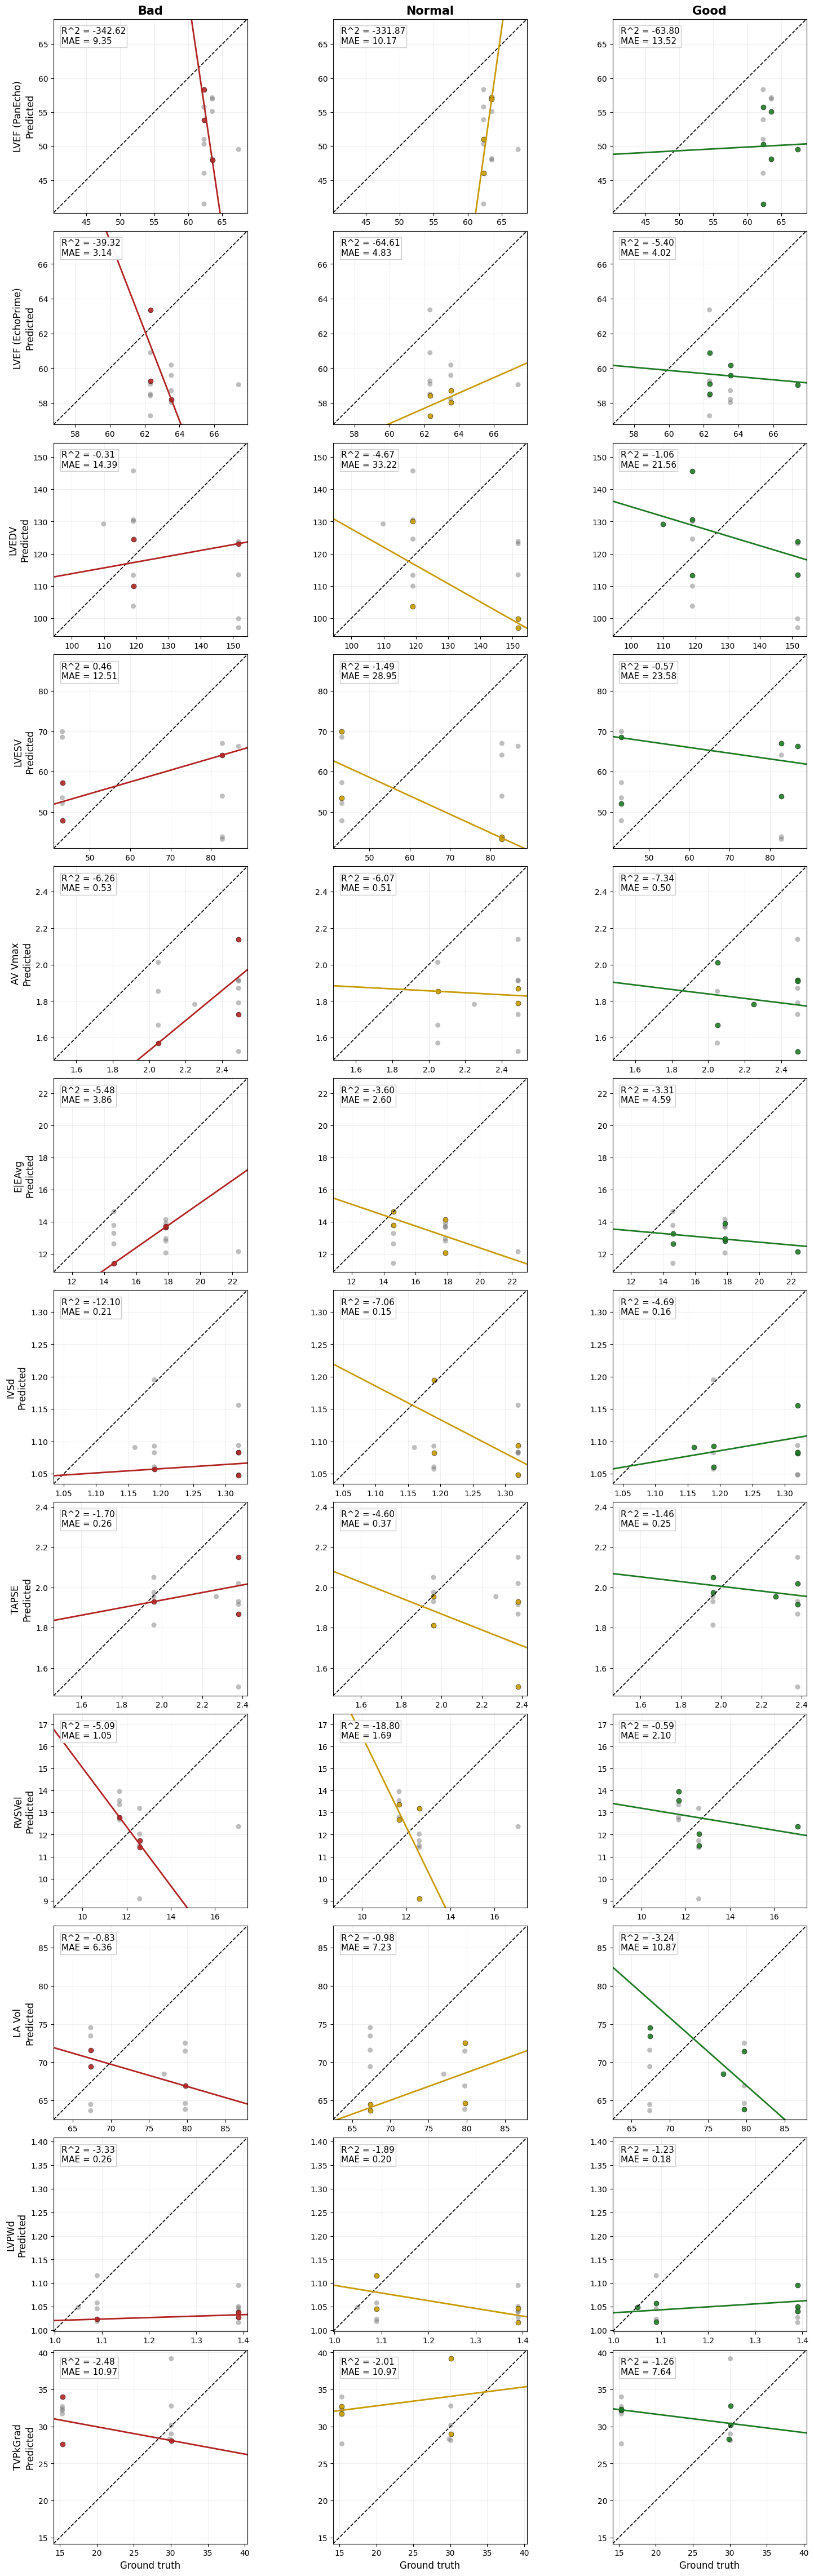

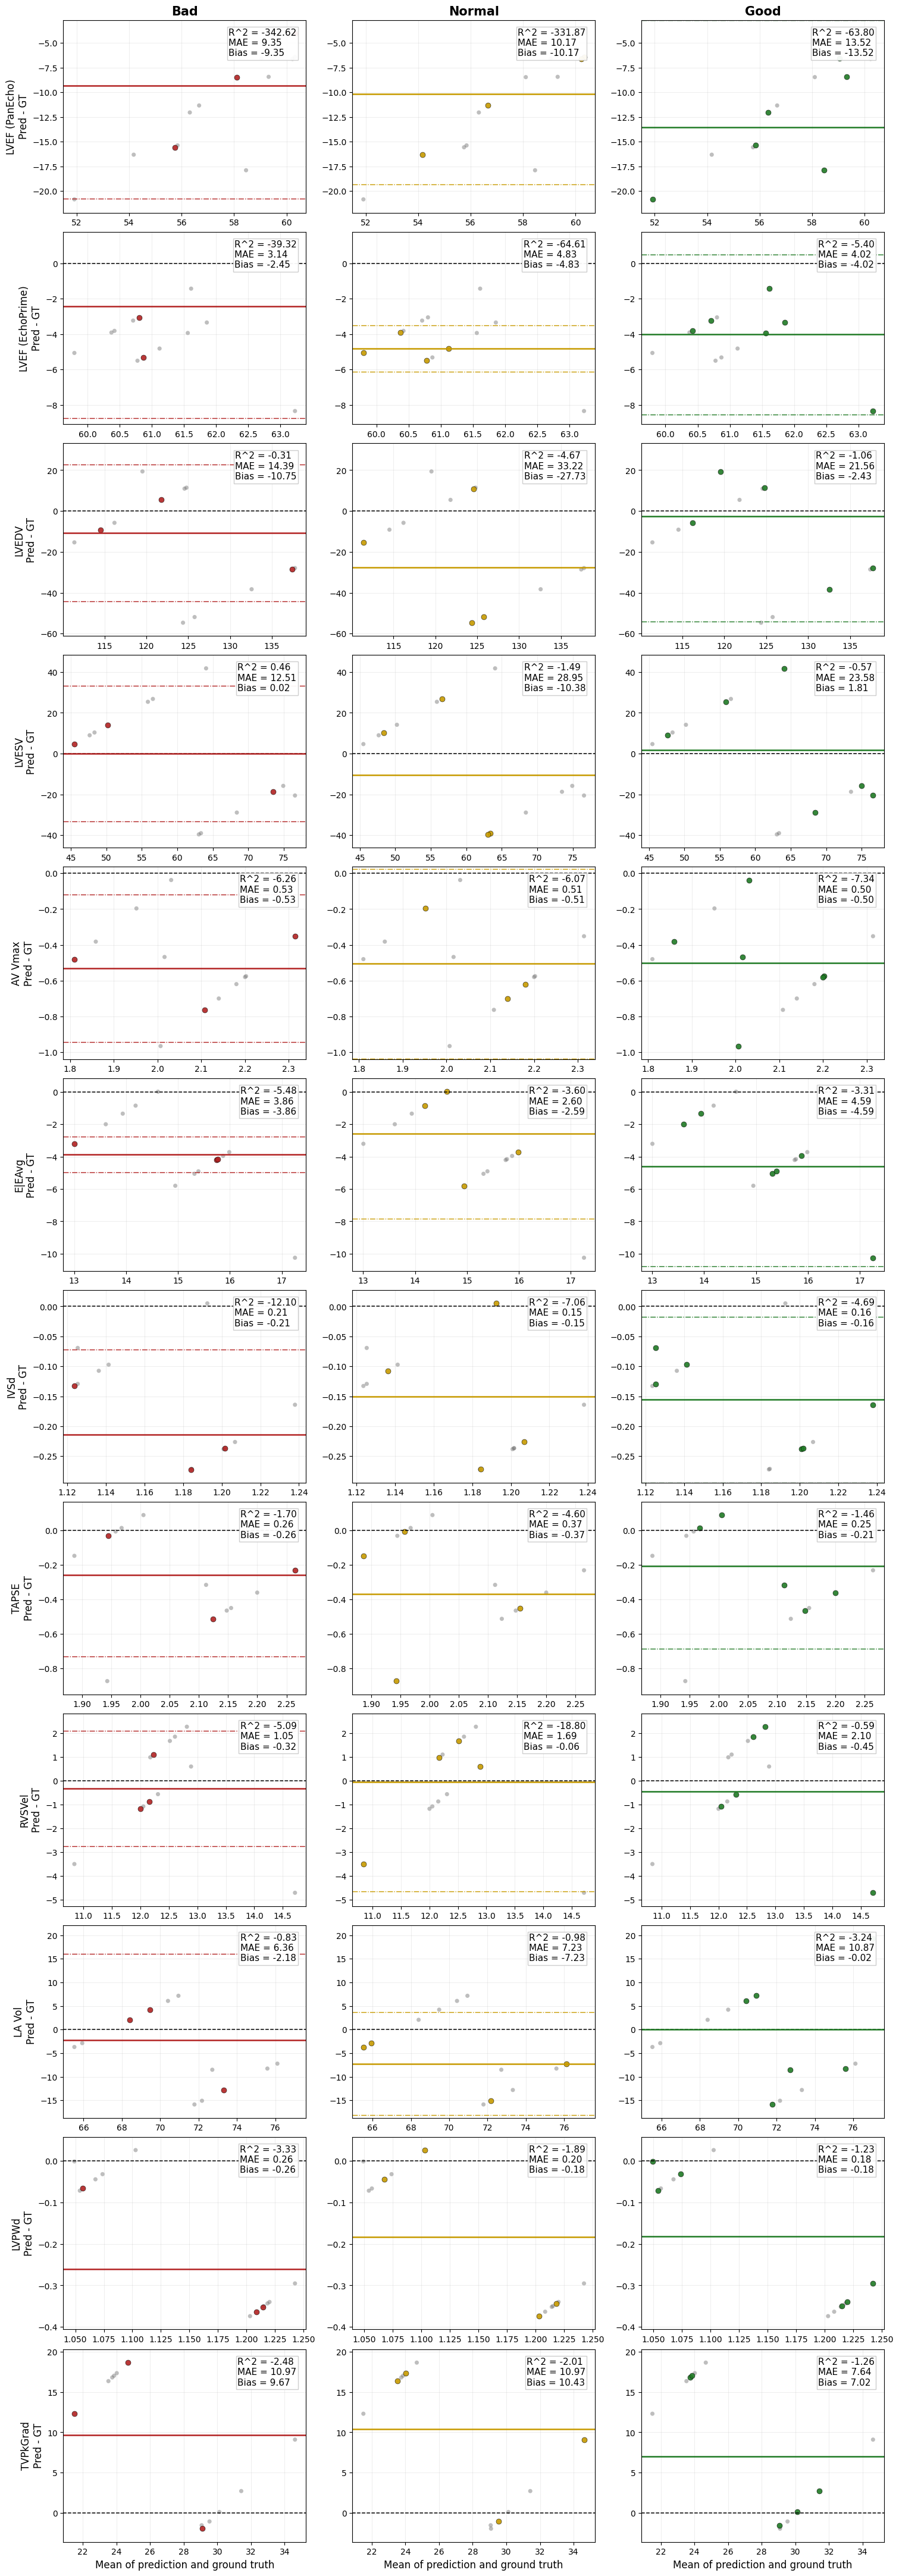

In [8]:
# Study-level scatter and Bland-Altman plots by quality
from pathlib import Path
from sklearn.metrics import mean_absolute_error, r2_score


panel_colors = {'bad': '#b22222', 'normal': '#c79a00', 'good': '#1f7a24'}
background_color = "#707070"
quality_order = ['bad', 'normal', 'good']

metric_plot_configs = [
    {
        'metric_key': 'EF_panecho',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'EF_pred',
        'gt_col': 'EF_gt',
        'quality_col': 'quality_study',
        'label': 'LVEF (PanEcho)',
    },
    {
        'metric_key': 'EF_echoprime',
        'source_name': 'echoprime_performance_df',
        'df_name': 'echoprime_performance_df',
        'pred_col': 'ejection_fraction',
        'gt_col': 'EF',
        'quality_col': 'quality_study',
        'label': 'LVEF (EchoPrime)',
    },
    {
        'metric_key': 'LVEDV',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'LVEDV_pred',
        'gt_col': 'LVEDV_gt',
        'quality_col': 'quality_study',
        'label': 'LVEDV',
    },
    {
        'metric_key': 'LVESV',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'LVESV_pred',
        'gt_col': 'LVESV_gt',
        'quality_col': 'quality_study',
        'label': 'LVESV',
    },
    {
        'metric_key': 'AVPkVel(m|s)',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'AVPkVel(m|s)_pred',
        'gt_col': 'AVPkVel(m|s)_gt',
        'quality_col': 'quality_study',
        'label': 'AV Vmax',
    },
    {
        'metric_key': 'E|EAvg',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'E|EAvg_pred',
        'gt_col': 'E|EAvg_gt',
        'quality_col': 'quality_study',
        'label': 'E|EAvg',
    },
    {
        'metric_key': 'IVSd',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'IVSd_pred',
        'gt_col': 'IVSd_gt',
        'quality_col': 'quality_study',
        'label': 'IVSd',
    },
    {
        'metric_key': 'TAPSE',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'TAPSE_pred',
        'gt_col': 'TAPSE_gt',
        'quality_col': 'quality_study',
        'label': 'TAPSE',
    },
    {
        'metric_key': 'RVSVel',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'RVSVel_pred',
        'gt_col': 'RVSVel_gt',
        'quality_col': 'quality_study',
        'label': 'RVSVel',
    },
    {
        'metric_key': 'LAVol',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'LAVol_pred',
        'gt_col': 'LAVol_gt',
        'quality_col': 'quality_study',
        'label': 'LA Vol',
    },
    {
        'metric_key': 'LVPWd',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'LVPWd_pred',
        'gt_col': 'LVPWd_gt',
        'quality_col': 'quality_study',
        'label': 'LVPWd',
    },
    {
        'metric_key': 'TVPkGrad',
        'source_name': 'performance_df',
        'df_name': 'performance_df',
        'pred_col': 'TVPkGrad_pred',
        'gt_col': 'TVPkGrad_gt',
        'quality_col': 'quality_study',
        'label': 'TVPkGrad',
    },
]

def safe_metric_summary(x_values, y_values):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    valid_mask = (~np.isnan(x_values)) & (~np.isnan(y_values))
    x_values = x_values[valid_mask]
    y_values = y_values[valid_mask]
    if len(x_values) == 0:
        return np.nan, np.nan
    mae_value = mean_absolute_error(x_values, y_values)
    if len(x_values) < 2 or np.unique(x_values).size < 2:
        r2_value = np.nan
    else:
        try:
            r2_value = r2_score(x_values, y_values)
        except Exception:
            r2_value = np.nan
    return float(mae_value), float(r2_value) if not pd.isna(r2_value) else np.nan

def build_plot_spec(config):
    if config['df_name'] not in globals():
        print(f"Skipping {config['label']}: dataframe '{config['df_name']}' is not available. Run the cells above first.")
        return None

    source_df = globals()[config['df_name']].copy()
    required_columns = [config['pred_col'], config['gt_col'], config['quality_col']]
    missing_columns = [col for col in required_columns if col not in source_df.columns]
    if missing_columns:
        print(
            f"Skipping {config['label']}: missing columns in {config['source_name']}: {missing_columns}."
        )
        return None

    if 'patient_id' not in source_df.columns:
        print(f"Skipping {config['label']}: missing patient_id in {config['source_name']}.")
        return None

    plot_df = source_df[['patient_id', config['pred_col'], config['gt_col'], config['quality_col']]].copy()
    plot_df = plot_df.rename(columns={config['quality_col']: 'plot_quality'})
    plot_df[config['pred_col']] = pd.to_numeric(plot_df[config['pred_col']], errors='coerce')
    plot_df[config['gt_col']] = pd.to_numeric(plot_df[config['gt_col']], errors='coerce')
    plot_df = plot_df.dropna(subset=[config['pred_col'], config['gt_col'], 'plot_quality']).copy()

    if len(plot_df) == 0:
        print(f"Skipping {config['label']}: no valid rows after filtering.")
        return None

    return {
        'label': config['label'],
        'pred_col': config['pred_col'],
        'gt_col': config['gt_col'],
        'study_df': plot_df,
    }

plot_specs = []
for config in metric_plot_configs:
    spec = build_plot_spec(config)
    if spec is not None:
        plot_specs.append(spec)

if len(plot_specs) == 0:
    print('No study-level scatter/Bland-Altman plot data available.')
else:
    scatter_fig, scatter_axes = plt.subplots(
        len(plot_specs), 3,
        figsize=(15, max(3.8 * len(plot_specs), 6)),
        squeeze=False,
        constrained_layout=True
    )

    bland_fig, bland_axes = plt.subplots(
        len(plot_specs), 3,
        figsize=(15, max(3.6 * len(plot_specs), 6)),
        squeeze=False,
        constrained_layout=True
    )

    for row_idx, spec in enumerate(plot_specs):
        study_df = spec['study_df'].copy()
        pred_col = spec['pred_col']
        gt_col = spec['gt_col']
        metric_label = spec['label']

        all_x = study_df[gt_col].to_numpy(dtype=float)
        all_y = study_df[pred_col].to_numpy(dtype=float)
        all_scatter_vals = np.concatenate([all_x, all_y])
        scatter_vmin = np.nanmin(all_scatter_vals)
        scatter_vmax = np.nanmax(all_scatter_vals)
        if not np.isfinite(scatter_vmin) or not np.isfinite(scatter_vmax):
            scatter_vmin, scatter_vmax = 0.0, 1.0
        elif np.isclose(scatter_vmin, scatter_vmax):
            scatter_pad = max(abs(scatter_vmin) * 0.1, 1.0)
            scatter_vmin -= scatter_pad
            scatter_vmax += scatter_pad
        else:
            scatter_pad = 0.05 * (scatter_vmax - scatter_vmin)
            scatter_vmin -= scatter_pad
            scatter_vmax += scatter_pad
        xx = np.linspace(scatter_vmin, scatter_vmax, 200)

        all_means = ((study_df[pred_col] + study_df[gt_col]) / 2.0).to_numpy(dtype=float)
        all_diffs = (study_df[pred_col] - study_df[gt_col]).to_numpy(dtype=float)
        bland_xmin = np.nanmin(all_means)
        bland_xmax = np.nanmax(all_means)
        if not np.isfinite(bland_xmin) or not np.isfinite(bland_xmax):
            bland_xmin, bland_xmax = 0.0, 1.0
        elif np.isclose(bland_xmin, bland_xmax):
            bland_pad_x = max(abs(bland_xmin) * 0.1, 1.0)
            bland_xmin -= bland_pad_x
            bland_xmax += bland_pad_x
        else:
            bland_pad_x = 0.05 * (bland_xmax - bland_xmin)
            bland_xmin -= bland_pad_x
            bland_xmax += bland_pad_x

        bland_ymin = np.nanmin(all_diffs)
        bland_ymax = np.nanmax(all_diffs)
        if not np.isfinite(bland_ymin) or not np.isfinite(bland_ymax):
            bland_ymin, bland_ymax = -1.0, 1.0
        elif np.isclose(bland_ymin, bland_ymax):
            bland_pad_y = max(abs(bland_ymin) * 0.1, 1.0)
            bland_ymin -= bland_pad_y
            bland_ymax += bland_pad_y
        else:
            bland_pad_y = 0.08 * (bland_ymax - bland_ymin)
            bland_ymin -= bland_pad_y
            bland_ymax += bland_pad_y

        for col_idx, quality_name in enumerate(quality_order):
            scatter_ax = scatter_axes[row_idx, col_idx]
            bland_ax = bland_axes[row_idx, col_idx]

            sub = study_df[study_df['plot_quality'] == quality_name].copy()
            background = study_df[study_df['plot_quality'] != quality_name].copy()

            if len(sub) == 0:
                scatter_ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=scatter_ax.transAxes, fontsize=12)
                scatter_ax.set_axis_off()
                bland_ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=bland_ax.transAxes, fontsize=12)
                bland_ax.set_axis_off()
                continue

            x = sub[gt_col].to_numpy(dtype=float)
            y = sub[pred_col].to_numpy(dtype=float)
            mae_value, r2_value = safe_metric_summary(x, y)

            if len(background) > 0:
                bg_x = background[gt_col].to_numpy(dtype=float)
                bg_y = background[pred_col].to_numpy(dtype=float)
                scatter_ax.scatter(
                    bg_x, bg_y,
                    color=background_color, edgecolor='none', alpha=0.45, s=42, zorder=1
                )

            scatter_ax.scatter(
                x, y,
                color=panel_colors[quality_name], edgecolor='black', linewidth=0.4, alpha=0.9, s=42, zorder=2
            )

            scatter_ax.plot(xx, xx, color='black', linestyle='--', linewidth=1.2)
            if len(sub) >= 2 and np.unique(x).size >= 2:
                slope, intercept = np.polyfit(x, y, 1)
                scatter_ax.plot(xx, slope * xx + intercept, color=panel_colors[quality_name], linewidth=2.0)

            if row_idx == 0:
                scatter_ax.set_title(quality_name.capitalize(), fontsize=15, fontweight='bold')
            if col_idx == 0:
                scatter_ax.set_ylabel(f'{metric_label}\nPredicted', fontsize=12)
            else:
                scatter_ax.set_ylabel('')
            if row_idx == len(plot_specs) - 1:
                scatter_ax.set_xlabel('Ground truth', fontsize=12)
            else:
                scatter_ax.set_xlabel('')

            scatter_ax.legend(
                handles=[],
                title=f'R^2 = {r2_value:.2f}\nMAE = {mae_value:.2f}',
                loc='upper left',
                bbox_to_anchor=(0.03, 0.97),
                borderpad=0.8,
                labelspacing=0.7,
                handlelength=0,
                handletextpad=0,
                fontsize=2,
                title_fontsize=11,
                frameon=True,
                framealpha=0.95,
            )
            scatter_ax.tick_params(axis='both', labelsize=10)
            scatter_ax.grid(alpha=0.2)
            scatter_ax.set_xlim(scatter_vmin, scatter_vmax)
            scatter_ax.set_ylim(scatter_vmin, scatter_vmax)
            scatter_ax.set_aspect('equal', adjustable='box')

            sub_means = ((sub[pred_col] + sub[gt_col]) / 2.0).to_numpy(dtype=float)
            sub_diffs = (sub[pred_col] - sub[gt_col]).to_numpy(dtype=float)
            bg_means = ((background[pred_col] + background[gt_col]) / 2.0).to_numpy(dtype=float) if len(background) > 0 else np.asarray([], dtype=float)
            bg_diffs = (background[pred_col] - background[gt_col]).to_numpy(dtype=float) if len(background) > 0 else np.asarray([], dtype=float)
            bias = float(np.mean(sub_diffs)) if len(sub_diffs) > 0 else np.nan
            sd_diff = float(np.std(sub_diffs, ddof=1)) if len(sub_diffs) > 1 else np.nan
            loa_low = float(bias - 1.96 * sd_diff) if not pd.isna(sd_diff) else np.nan
            loa_high = float(bias + 1.96 * sd_diff) if not pd.isna(sd_diff) else np.nan

            if len(bg_means) > 0:
                bland_ax.scatter(
                    bg_means, bg_diffs,
                    color=background_color, edgecolor='none', alpha=0.45, s=26, zorder=1
                )

            bland_ax.scatter(
                sub_means, sub_diffs,
                color=panel_colors[quality_name], edgecolor='black', linewidth=0.4, alpha=0.9, s=42, zorder=2
            )

            bland_ax.axhline(0.0, color='black', linestyle='--', linewidth=1.1)
            bland_ax.axhline(bias, color=panel_colors[quality_name], linestyle='-', linewidth=1.8)
            if not pd.isna(loa_low):
                bland_ax.axhline(loa_low, color=panel_colors[quality_name], linestyle='-.', linewidth=1.0)
            if not pd.isna(loa_high):
                bland_ax.axhline(loa_high, color=panel_colors[quality_name], linestyle='-.', linewidth=1.0)

            if row_idx == 0:
                bland_ax.set_title(quality_name.capitalize(), fontsize=15, fontweight='bold')
            if col_idx == 0:
                bland_ax.set_ylabel(f'{metric_label}\nPred - GT', fontsize=12)
            else:
                bland_ax.set_ylabel('')
            if row_idx == len(plot_specs) - 1:
                bland_ax.set_xlabel('Mean of prediction and ground truth', fontsize=12)
            else:
                bland_ax.set_xlabel('')

            bland_ax.legend(
                handles=[],
                title=f'R^2 = {r2_value:.2f}\nMAE = {mae_value:.2f}\nBias = {bias:.2f}',
                loc='upper right',
                bbox_to_anchor=(0.97, 0.97),
                borderpad=0.8,
                labelspacing=0.7,
                handlelength=0,
                handletextpad=0,
                fontsize=2,
                title_fontsize=11,
                frameon=True,
                framealpha=0.95,
            )
            bland_ax.tick_params(axis='both', labelsize=10)
            bland_ax.grid(alpha=0.2)
            bland_ax.set_xlim(bland_xmin, bland_xmax)
            bland_ax.set_ylim(bland_ymin, bland_ymax)

    scatter_output = output_dir / 'measurement_scatter_by_quality.png'
    bland_output = output_dir / 'measurement_bland_altman_by_quality.png'
    scatter_fig.savefig(scatter_output, dpi=200, bbox_inches='tight')
    bland_fig.savefig(bland_output, dpi=200, bbox_inches='tight')
    plt.show()


### 5.1 · Disease Labels Derived from Measurements

When direct binary disease annotations are unavailable, labels are derived from quantitative measurements using established clinical thresholds. Labels are computed independently for **ground truth**, **PanEcho**, and **EchoPrime**, enabling cross-source performance comparison.

### Clinical Thresholds Applied

| Disease | Criterion | Notes |
|---------|-----------|-------|
| **LV Systolic Dysfunction** | LVEF ≤ 40% | Applied to all three sources |
| **Aortic Stenosis** | Aortic peak velocity ≥ 3.0 m/s | — |
| **LV Dilation** | See table below | Sex-specific; BSA-indexed thresholds preferred |
| **Abnormal LV Wall Thickness** | max(LVPWd, IVSd) > sex-specific cutoff | ♂ > 1.4 cm · ♀ > 1.3 cm |
| **LA Dilation** | BSA-indexed LA volume ≥ 42.0 mL/m² | Requires BSA to be present |

**LV Dilation thresholds (LVEDV)**

| BSA available? | Male | Female |
|----------------|------|--------|
| Yes (BSA-indexed, mL/m²) | LVEDV/BSA > 90 mL/m² | LVEDV/BSA > 71 mL/m² |
| No (absolute, mL) | LVEDV > 175 mL | LVEDV > 121 mL |

In [9]:
from pathlib import Path


if 'compute_binary_classification_stats' not in globals():
    def compute_binary_classification_stats(y_true, y_score, threshold=0.5):
        y_true = np.asarray(y_true, dtype=float)
        y_score = np.asarray(y_score, dtype=float)
        valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
        y_true = y_true[valid_mask].astype(int)
        y_score = y_score[valid_mask]
        if len(y_true) == 0:
            return {
                'threshold': threshold,
                'tp': 0,
                'tn': 0,
                'fp': 0,
                'fn': 0,
                'sensitivity': np.nan,
                'specificity': np.nan,
                'ppv': np.nan,
                'npv': np.nan,
                'accuracy': np.nan,
            }

        y_pred = (y_score >= threshold).astype(int)
        tp = int(np.sum((y_true == 1) & (y_pred == 1)))
        tn = int(np.sum((y_true == 0) & (y_pred == 0)))
        fp = int(np.sum((y_true == 0) & (y_pred == 1)))
        fn = int(np.sum((y_true == 1) & (y_pred == 0)))

        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
        ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        npv = tn / (tn + fn) if (tn + fn) > 0 else np.nan
        accuracy = (tp + tn) / len(y_true) if len(y_true) > 0 else np.nan

        return {
            'threshold': threshold,
            'tp': tp,
            'tn': tn,
            'fp': fp,
            'fn': fn,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'ppv': ppv,
            'npv': npv,
            'accuracy': accuracy,
        }

def get_first_existing_column(df_in, candidates):
    for candidate in candidates:
        if candidate in df_in.columns:
            return candidate
    return None

def ensure_patient_id_column(df_in, df_name):
    if 'patient_id' in df_in.columns:
        return df_in.copy()

    df_out = df_in.reset_index().copy()
    if 'patient_id' in df_out.columns:
        return df_out
    if 'index' in df_out.columns and not isinstance(df_in.index, pd.RangeIndex):
        return df_out.rename(columns={'index': 'patient_id'})

    raise KeyError(f"{df_name} does not contain a usable 'patient_id' column or index.")

def to_float_or_nan(value):
    numeric_value = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.isna(numeric_value):
        return np.nan
    return float(numeric_value)

def normalize_sex_value(value):
    if pd.isna(value):
        return np.nan
    value_str = str(value).strip().lower()
    if value_str in {'m', 'male'}:
        return 'male'
    if value_str in {'f', 'female'}:
        return 'female'
    return np.nan

def index_volume_by_bsa(volume_value, bsa_value):
    volume_value = to_float_or_nan(volume_value)
    bsa_value = to_float_or_nan(bsa_value)
    if pd.isna(volume_value) or pd.isna(bsa_value) or bsa_value <= 0:
        return np.nan
    return float(volume_value / bsa_value)

def label_lvef_dysfunction(lvef_value):
    lvef_value = to_float_or_nan(lvef_value)
    if pd.isna(lvef_value):
        return np.nan
    return int(lvef_value <= 40.0)

def label_aortic_stenosis(vmax_value):
    vmax_value = to_float_or_nan(vmax_value)
    if pd.isna(vmax_value):
        return np.nan
    return int(vmax_value >= 3.0)

def label_lv_dilation(lvedv_value, sex_value, bsa_value):
    lvedv_value = to_float_or_nan(lvedv_value)
    sex_value = normalize_sex_value(sex_value)
    bsa_value = to_float_or_nan(bsa_value)
    if pd.isna(lvedv_value) or pd.isna(sex_value):
        return np.nan

    if not pd.isna(bsa_value) and bsa_value > 0:
        indexed_lvedv = float(lvedv_value / bsa_value)
        threshold = 90.0 if sex_value == 'male' else 71.0
        return int(indexed_lvedv > threshold)

    threshold = 175.0 if sex_value == 'male' else 121.0
    return int(lvedv_value > threshold)

def label_abnormal_lv_thickness(lvpwd_value, ivsd_value, sex_value):
    lvpwd_value = to_float_or_nan(lvpwd_value)
    ivsd_value = to_float_or_nan(ivsd_value)
    sex_value = normalize_sex_value(sex_value)
    if pd.isna(lvpwd_value) or pd.isna(ivsd_value) or pd.isna(sex_value):
        return np.nan

    # The repo stores wall thicknesses in cm, so convert 14 mm / 13 mm to cm.
    threshold = 1.4 if sex_value == 'male' else 1.3
    return int(max(lvpwd_value, ivsd_value) >= threshold)

def label_la_dilation(lavol_value, bsa_value):
    indexed_lavol = index_volume_by_bsa(lavol_value, bsa_value)
    if pd.isna(indexed_lavol):
        return np.nan
    return int(indexed_lavol >= 42.0)

def build_source_value_df(source_df, source_name, feature_aliases):
    source_values_df = source_df[['patient_id']].drop_duplicates().copy()
    for feature_name, candidates in feature_aliases.items():
        source_col = get_first_existing_column(source_df, candidates)
        if source_col is None:
            source_values_df[f'{feature_name}_{source_name}_value'] = np.nan
            continue
        feature_df = source_df[['patient_id', source_col]].drop_duplicates(subset=['patient_id']).rename(
            columns={source_col: f'{feature_name}_{source_name}_value'}
        )
        source_values_df = source_values_df.merge(feature_df, on='patient_id', how='left')
    return source_values_df

measurement_disease_feature_aliases = {
    'gt': {
        'lvef': ['LVEF', 'EF', 'ejection_fraction'],
        'vmax_aortic': ['Vmax_aortic', 'AVPkVel(m|s)', 'AVPkVel'],
        'lvedv': ['LVEDV'],
        'lvpwd': ['LVPWd', 'LVPW'],
        'ivsd': ['IVSd', 'IVS'],
        'lavol': ['LAVol', 'LA_volume'],
    },
    'panecho': {
        'lvef': ['LVEF', 'EF', 'ejection_fraction'],
        'vmax_aortic': ['Vmax_aortic', 'AVPkVel(m|s)', 'AVPkVel'],
        'lvedv': ['LVEDV'],
        'lvpwd': ['LVPWd', 'LVPW'],
        'ivsd': ['IVSd', 'IVS'],
        'lavol': ['LAVol', 'LA_volume'],
    },
    'echoprime': {
        'lvef': ['ejection_fraction', 'LVEF', 'EF'],
        'vmax_aortic': ['Vmax_aortic', 'AVPkVel(m|s)', 'AVPkVel'],
        'lvedv': ['LVEDV'],
        'lvpwd': ['LVPWd', 'LVPW'],
        'ivsd': ['IVSd', 'IVS'],
        'lavol': ['LAVol', 'LA_volume'],
    },
}

ground_truth_measurement_disease = ensure_patient_id_column(ground_truth, 'ground_truth')
panecho_study_measurement_disease = ensure_patient_id_column(panecho_study, 'panecho_study')
echoprime_measurement_disease = ensure_patient_id_column(echoprime, 'echoprime')
demographics_measurement_disease = ensure_patient_id_column(demographics, 'demographics')

all_measurement_disease_patient_ids = pd.concat(
    [
        ground_truth_measurement_disease[['patient_id']],
        panecho_study_measurement_disease[['patient_id']],
        echoprime_measurement_disease[['patient_id']],
        demographics_measurement_disease[['patient_id']],
    ],
    ignore_index=True
).dropna().drop_duplicates().sort_values('patient_id').reset_index(drop=True)

measurement_disease_label_df = all_measurement_disease_patient_ids.copy()

gt_sex_col = get_first_existing_column(ground_truth_measurement_disease, ['sex', 'Sex'])
demo_sex_col = get_first_existing_column(demographics_measurement_disease, ['sex', 'Sex'])
gt_bsa_col = get_first_existing_column(ground_truth_measurement_disease, ['BSA', 'bsa'])
demo_bsa_col = get_first_existing_column(demographics_measurement_disease, ['BSA', 'bsa'])

if gt_sex_col is not None:
    measurement_disease_label_df = measurement_disease_label_df.merge(
        ground_truth_measurement_disease[['patient_id', gt_sex_col]].drop_duplicates(subset=['patient_id']).rename(
            columns={gt_sex_col: 'sex_gt'}
        ),
        on='patient_id',
        how='left'
    )
else:
    measurement_disease_label_df['sex_gt'] = np.nan

if demo_sex_col is not None:
    measurement_disease_label_df = measurement_disease_label_df.merge(
        demographics_measurement_disease[['patient_id', demo_sex_col]].drop_duplicates(subset=['patient_id']).rename(
            columns={demo_sex_col: 'sex_demographics'}
        ),
        on='patient_id',
        how='left'
    )
else:
    measurement_disease_label_df['sex_demographics'] = np.nan

if gt_bsa_col is not None:
    measurement_disease_label_df = measurement_disease_label_df.merge(
        ground_truth_measurement_disease[['patient_id', gt_bsa_col]].drop_duplicates(subset=['patient_id']).rename(
            columns={gt_bsa_col: 'bsa_gt'}
        ),
        on='patient_id',
        how='left'
    )
else:
    measurement_disease_label_df['bsa_gt'] = np.nan

if demo_bsa_col is not None:
    measurement_disease_label_df = measurement_disease_label_df.merge(
        demographics_measurement_disease[['patient_id', demo_bsa_col]].drop_duplicates(subset=['patient_id']).rename(
            columns={demo_bsa_col: 'bsa_demographics'}
        ),
        on='patient_id',
        how='left'
    )
else:
    measurement_disease_label_df['bsa_demographics'] = np.nan

measurement_disease_label_df['sex'] = measurement_disease_label_df['sex_gt'].combine_first(
    measurement_disease_label_df['sex_demographics']
)
measurement_disease_label_df['BSA'] = pd.to_numeric(
    measurement_disease_label_df['bsa_gt'].combine_first(measurement_disease_label_df['bsa_demographics']),
    errors='coerce'
)
measurement_disease_label_df['sex'] = measurement_disease_label_df['sex'].apply(normalize_sex_value)

measurement_disease_sources = {
    'gt': ground_truth_measurement_disease.copy(),
    'panecho': panecho_study_measurement_disease.copy(),
    'echoprime': echoprime_measurement_disease.copy(),
}
for source_name, source_df in measurement_disease_sources.items():
    source_values_df = build_source_value_df(
        source_df,
        source_name=source_name,
        feature_aliases=measurement_disease_feature_aliases[source_name],
    )
    measurement_disease_label_df = measurement_disease_label_df.merge(
        source_values_df,
        on='patient_id',
        how='left'
    )

for source_name in ['gt', 'panecho', 'echoprime']:
    measurement_disease_label_df[f'lvedv_indexed_{source_name}'] = measurement_disease_label_df.apply(
        lambda row: index_volume_by_bsa(row[f'lvedv_{source_name}_value'], row['BSA']),
        axis=1
    )
    measurement_disease_label_df[f'lavol_indexed_{source_name}'] = measurement_disease_label_df.apply(
        lambda row: index_volume_by_bsa(row[f'lavol_{source_name}_value'], row['BSA']),
        axis=1
    )
    measurement_disease_label_df[f'lv_dysfunction_{source_name}'] = measurement_disease_label_df[
        f'lvef_{source_name}_value'
    ].apply(label_lvef_dysfunction)
    measurement_disease_label_df[f'aortic_stenosis_{source_name}'] = measurement_disease_label_df[
        f'vmax_aortic_{source_name}_value'
    ].apply(label_aortic_stenosis)
    measurement_disease_label_df[f'lv_dilation_{source_name}'] = measurement_disease_label_df.apply(
        lambda row: label_lv_dilation(row[f'lvedv_{source_name}_value'], row['sex'], row['BSA']),
        axis=1
    )
    measurement_disease_label_df[f'abnormal_lv_thickness_{source_name}'] = measurement_disease_label_df.apply(
        lambda row: label_abnormal_lv_thickness(
            row[f'lvpwd_{source_name}_value'],
            row[f'ivsd_{source_name}_value'],
            row['sex']
        ),
        axis=1
    )
    measurement_disease_label_df[f'la_dilation_{source_name}'] = measurement_disease_label_df.apply(
        lambda row: label_la_dilation(row[f'lavol_{source_name}_value'], row['BSA']),
        axis=1
    )

measurement_disease_condition_order = [
    'lv_dysfunction',
    'aortic_stenosis',
    'lv_dilation',
    'abnormal_lv_thickness',
    'la_dilation',
]
measurement_disease_model_condition_map = {
    'panecho': measurement_disease_condition_order,
    'echoprime': ['lv_dysfunction'],
}
for condition_name in measurement_disease_condition_order:
    if condition_name == 'lv_dysfunction':
        continue
    measurement_disease_label_df[f'{condition_name}_echoprime'] = np.nan

measurement_disease_label_columns = ['patient_id']
for condition_name in measurement_disease_condition_order:
    measurement_disease_label_columns.extend([
        f'{condition_name}_gt',
        f'{condition_name}_panecho',
        f'{condition_name}_echoprime',
    ])

measurement_disease_labels_export_df = measurement_disease_label_df[
    measurement_disease_label_columns
].copy()
measurement_disease_labels_export_df = measurement_disease_labels_export_df.merge(
    quality_patient[['patient_id', 'quality_study']],
    on='patient_id',
    how='left'
)
measurement_disease_summary_rows = []
measurement_disease_summary_rng = np.random.default_rng(42)
measurement_disease_summary_metrics = ['accuracy', 'sensitivity', 'specificity', 'ppv', 'npv']
measurement_disease_quality_order = globals().get('quality_order', ['bad', 'normal', 'good'])
measurement_disease_overall_df = measurement_disease_labels_export_df.loc[
    measurement_disease_labels_export_df['quality_study'].isin(measurement_disease_quality_order)
].copy()
measurement_disease_quality_groups = [('overall', measurement_disease_overall_df)] + [
    (quality_name, measurement_disease_labels_export_df.loc[
        measurement_disease_labels_export_df['quality_study'] == quality_name
    ])
    for quality_name in measurement_disease_quality_order
]
for condition_name in measurement_disease_condition_order:
    gt_col = f'{condition_name}_gt'
    for model_name in ['panecho', 'echoprime']:
        if condition_name not in measurement_disease_model_condition_map[model_name]:
            continue
        pred_col = f'{condition_name}_{model_name}'
        for quality_name, quality_df in measurement_disease_quality_groups:
            paired_df = quality_df[[gt_col, pred_col]].dropna().copy()
            y_true = paired_df[gt_col].to_numpy(dtype=float)
            y_score = paired_df[pred_col].to_numpy(dtype=float)
            diagnostic_stats = compute_binary_classification_stats(
                y_true,
                y_score,
                threshold=0.5,
            )
            summary_row = {
                'condition': condition_name,
                'model': model_name,
                'quality': quality_name,
                'n_eval': int(len(paired_df)),
                'n_pos': int(np.sum(y_true == 1)),
                'accuracy': diagnostic_stats['accuracy'],
                'sensitivity': diagnostic_stats['sensitivity'],
                'specificity': diagnostic_stats['specificity'],
                'PPV': diagnostic_stats['ppv'],
                'NPV': diagnostic_stats['npv'],
            }
            for metric_name in measurement_disease_summary_metrics:
                _, boot_values = bootstrap_classification_metric_distribution(
                    y_true,
                    y_score,
                    metric_name=metric_name,
                    threshold=0.5,
                    n_boot=n_bootstrap_export,
                    rng=measurement_disease_summary_rng,
                )
                output_metric_name = metric_name.upper() if metric_name in ['ppv', 'npv'] else metric_name
                add_bootstrap_ci_columns(summary_row, output_metric_name, boot_values)
            measurement_disease_summary_rows.append(summary_row)

measurement_disease_summary_df = pd.DataFrame(measurement_disease_summary_rows)
measurement_disease_summary_df.to_csv(
    output_dir / 'disease_classification_from_measurements.csv',
    index=False
)

measurement_disease_manifest_rows = pd.DataFrame([
    {'file': 'disease_classification_from_measurements.csv', 'rows': len(measurement_disease_summary_df)},
])
if 'export_manifest' in globals():
    export_manifest = export_manifest.loc[
        ~export_manifest['file'].isin(measurement_disease_manifest_rows['file'])
    ].copy()
    export_manifest = pd.concat([export_manifest, measurement_disease_manifest_rows], ignore_index=True)

measurement_disease_summary_df


,condition,model,quality,n_eval,n_pos,accuracy,sensitivity,specificity,PPV,NPV,...,sensitivity_ci_high,n_bootstrap_specificity,specificity_ci_low,specificity_ci_high,n_bootstrap_PPV,PPV_ci_low,PPV_ci_high,n_bootstrap_NPV,NPV_ci_low,NPV_ci_high
0,lv_dysfunction,panecho,overall,13,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
1,lv_dysfunction,panecho,bad,3,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
2,lv_dysfunction,panecho,normal,4,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
3,lv_dysfunction,panecho,good,6,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
4,lv_dysfunction,echoprime,overall,13,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
5,lv_dysfunction,echoprime,bad,3,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
6,lv_dysfunction,echoprime,normal,4,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
7,lv_dysfunction,echoprime,good,6,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
8,aortic_stenosis,panecho,overall,12,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0
9,aortic_stenosis,panecho,bad,3,0,1.000000,NaN,1.0,NaN,1.000000,...,NaN,1000,1.0,1.0,0,NaN,NaN,1000,1.000000,1.0


---

## 6 · Quality-Aware Predictions 


This section implement prediction strategies that leverage EchoQuality scores to improve study-level AI outputs by down-weighting or excluding poor-quality acquisitions before aggregation.

In [10]:
# Section 6: quality-aware PanEcho aggregation and performance summaries
from pathlib import Path

quality_weight_threshold = 0.25
quality_weight_power = 2
quality_order_quality_aware = globals().get('quality_order', ['bad', 'normal', 'good'])
quality_groups_quality_aware = ['overall'] + list(quality_order_quality_aware)


def parse_quality_vector(quality_val):
    if isinstance(quality_val, str):
        return ast.literal_eval(quality_val)
    return quality_val


def get_quality_label(quality_val):
    quality_array = np.array(parse_quality_vector(quality_val), dtype=float)
    probs = softmax(quality_array)
    label = np.argmax(probs)
    return label


def weighted_mean_numeric(values, weights):
    values = pd.to_numeric(pd.Series(values), errors='coerce').to_numpy(dtype=float)
    weights = pd.to_numeric(pd.Series(weights), errors='coerce').to_numpy(dtype=float)
    valid_mask = (~np.isnan(values)) & (~np.isnan(weights)) & (weights > 0)
    if not valid_mask.any():
        return np.nan
    return float(np.average(values[valid_mask], weights=weights[valid_mask]))


def weighted_mean_array(values, weights):
    parsed_values = []
    parsed_weights = []
    for value, weight in zip(values, weights):
        weight = pd.to_numeric(pd.Series([weight]), errors='coerce').iloc[0]
        parsed_value = parse_array_string(value)
        if parsed_value is None or pd.isna(weight) or weight <= 0:
            continue
        parsed_values.append(parsed_value)
        parsed_weights.append(float(weight))

    if not parsed_values:
        return np.nan

    max_len = max(len(value) for value in parsed_values)
    values_padded = np.asarray([
        value + [np.nan] * (max_len - len(value))
        for value in parsed_values
    ], dtype=float)
    weights_array = np.asarray(parsed_weights, dtype=float)

    weighted_values = []
    for idx in range(max_len):
        column = values_padded[:, idx]
        valid_mask = ~np.isnan(column)
        if not valid_mask.any():
            weighted_values.append(np.nan)
        else:
            weighted_values.append(float(np.average(column[valid_mask], weights=weights_array[valid_mask])))
    return weighted_values


def build_quality_aware_panecho_study(video_level_df):
    study_df = pd.DataFrame(index=pd.Index(video_level_df['patient_id'].dropna().unique(), name='patient_id'))
    quality_prob = pd.to_numeric(video_level_df['prob_quality_lin'], errors='coerce')
    bad_low_quality_mask = (quality_prob < quality_weight_threshold) # & (video_level_df['quality_label'] == 'bad')
    included_df = video_level_df.loc[~bad_low_quality_mask].copy()
    included_df['quality_weight'] = pd.to_numeric(
        included_df['prob_quality_lin'], errors='coerce'
    ) ** quality_weight_power

    for metric_name, views_loop in metric_groups.items():
        if metric_name not in included_df.columns:
            continue
        metric_df = included_df.loc[
            included_df['view'].isin(views_loop),
            ['patient_id', metric_name, 'quality_weight']
        ].dropna(subset=['patient_id'])
        study_df[metric_name] = metric_df.groupby('patient_id').apply(
            lambda group: weighted_mean_numeric(group[metric_name], group['quality_weight'])
        )

    for task in tasks_binary:
        source_col = task['source_col']
        if source_col not in included_df.columns:
            continue
        task_df = included_df.loc[
            included_df['view'].isin(structure_views[task['structure']]),
            ['patient_id', source_col, 'quality_weight']
        ].dropna(subset=['patient_id'])
        study_df[task['output_col']] = task_df.groupby('patient_id').apply(
            lambda group: weighted_mean_numeric(group[source_col], group['quality_weight'])
        )

    for task in tasks_multiclass:
        source_col = task['source_col']
        if source_col not in included_df.columns:
            continue
        task_df = included_df.loc[
            included_df['view'].isin(structure_views[task['structure']]),
            ['patient_id', source_col, 'quality_weight']
        ].dropna(subset=['patient_id'])
        study_df[task['output_col']] = task_df.groupby('patient_id').apply(
            lambda group: weighted_mean_array(group[source_col], group['quality_weight'])
        )

    if 'PericardialEffusion' in study_df.columns:
        study_df['pericardial-effusion'] = study_df['PericardialEffusion']

    return study_df.reset_index()


def quality_subset_eval_df(eval_df, quality_name):
    if quality_name == 'overall':
        return eval_df.loc[eval_df['quality_study_view'].isin(quality_order_quality_aware)].copy()
    return eval_df.loc[eval_df['quality_study_view'] == quality_name].copy()


quality_aware = video_df.copy()
quality_aware['quality_label'] = quality_aware['quality'].apply(get_quality_label)
quality_aware['quality'] = quality_aware['quality'].apply(parse_quality_vector).apply(lambda x: softmax(x))
quality_aware['quality_label'] = quality_aware['quality_label'].map({0: 'bad', 1: 'normal', 2: 'good'})
quality_aware['prob_quality_lin'] = quality_aware['quality'].apply(lambda x: (x[1] + 2 * x[2]) / 2)

panecho_quality_aware = panecho.merge(
    quality_aware[['path', 'quality_label', 'prob_quality_lin']],
    on='path',
    how='left'
)
ground_truth_GT = ground_truth.rename(
    columns={col: f'{col}_GT' for col in ground_truth.columns if col != 'patient_id'}
)
panecho_quality_aware = panecho_quality_aware.merge(
    ground_truth_GT,
    on='patient_id',
    how='left'
)
panecho_quality_aware = panecho_quality_aware.merge(
    quality_patient[['patient_id', 'quality_study_view']],
    on='patient_id',
    how='left'
)
panecho_quality_aware = panecho_quality_aware.merge(
    demographics[['patient_id', 'sex', 'BSA']],
    on='patient_id',
    how='left',
    suffixes=('', '_demographics')
)

panecho_quality_aware_model = panecho.merge(
    quality_aware[['path', 'quality_label', 'prob_quality_lin']],
    on='path',
    how='left'
)
panecho_quality_aware_model['patient_id'] = panecho_quality_aware_model['path'].apply(extract_patient_id_from_path)
if 'view' not in panecho_quality_aware_model.columns:
    panecho_quality_aware_model = panecho_quality_aware_model.merge(
        view_ident[['path', 'view']].drop_duplicates(subset=['path']),
        on='path',
        how='left'
    )
panecho_quality_aware_model['view'] = panecho_quality_aware_model['view'].astype(str).str.strip().str.upper()

panecho_quality_aware_study = build_quality_aware_panecho_study(panecho_quality_aware_model)

panecho_original_quality_eval = panecho_study.merge(
    quality_patient[['patient_id', 'quality_study_view']],
    on='patient_id',
    how='left'
)
panecho_quality_aware_eval = panecho_quality_aware_study.merge(
    quality_patient[['patient_id', 'quality_study_view']],
    on='patient_id',
    how='left'
)

# Measures: full statistics original vs quality-aware
quality_aware_measure_rows = []
quality_aware_measure_bootstrap_map = {}
quality_aware_measure_rng = np.random.default_rng(42)
for mapping in measurement_mappings:
    measure_name = mapping['metric']
    gt_col = mapping['ground_truth']
    pred_col = mapping.get('panecho')
    if gt_col not in ground_truth.columns or pred_col not in panecho_original_quality_eval.columns:
        continue
    if pred_col not in panecho_quality_aware_eval.columns:
        continue

    original_eval_df = ground_truth[['patient_id', gt_col]].rename(columns={gt_col: 'y_true'}).merge(
        panecho_original_quality_eval[['patient_id', 'quality_study_view', pred_col]].rename(columns={pred_col: 'y_pred'}),
        on='patient_id',
        how='inner'
    )
    quality_aware_eval_df = ground_truth[['patient_id', gt_col]].rename(columns={gt_col: 'y_true'}).merge(
        panecho_quality_aware_eval[['patient_id', 'quality_study_view', pred_col]].rename(columns={pred_col: 'y_pred'}),
        on='patient_id',
        how='inner'
    )

    for quality_name in quality_groups_quality_aware:
        original_subset = quality_subset_eval_df(original_eval_df, quality_name)
        quality_aware_subset = quality_subset_eval_df(quality_aware_eval_df, quality_name)
        original_stats, original_r2_boot = compute_measurement_statistics(
            measure_name,
            'panecho_original',
            quality_name,
            original_subset,
            'y_true',
            'y_pred',
            n_boot=n_bootstrap_export,
            rng=quality_aware_measure_rng,
        )
        quality_aware_stats, quality_aware_r2_boot = compute_measurement_statistics(
            measure_name,
            'panecho_weighted',
            quality_name,
            quality_aware_subset,
            'y_true',
            'y_pred',
            n_boot=n_bootstrap_export,
            rng=quality_aware_measure_rng,
        )
        quality_aware_measure_rows.extend([original_stats, quality_aware_stats])
        quality_aware_measure_bootstrap_map[('panecho_original', measure_name, quality_name)] = original_r2_boot
        quality_aware_measure_bootstrap_map[('panecho_weighted', measure_name, quality_name)] = quality_aware_r2_boot

quality_aware_measure_results_df = pd.DataFrame(quality_aware_measure_rows)

for model_name in quality_aware_measure_results_df['model'].dropna().unique():
    for measure_name in quality_aware_measure_results_df.loc[
        quality_aware_measure_results_df['model'] == model_name, 'metric'
    ].dropna().unique():
        pairwise_results = {}
        for quality_a, quality_b in comparison_pairs:
            p_value = two_sided_bootstrap_pvalue(
                quality_aware_measure_bootstrap_map.get((model_name, measure_name, quality_a), np.asarray([], dtype=float)),
                quality_aware_measure_bootstrap_map.get((model_name, measure_name, quality_b), np.asarray([], dtype=float)),
            )
            pairwise_results[f'p_value_r2_{quality_a}_vs_{quality_b}'] = p_value

        mask = (
            (quality_aware_measure_results_df['model'] == model_name)
            & (quality_aware_measure_results_df['metric'] == measure_name)
        )
        for column_name, value in pairwise_results.items():
            quality_aware_measure_results_df.loc[mask, column_name] = value

for measure_name in quality_aware_measure_results_df['metric'].dropna().unique():
    for quality_name in quality_groups_quality_aware:
        p_value = two_sided_bootstrap_pvalue(
            quality_aware_measure_bootstrap_map.get(('panecho_original', measure_name, quality_name), np.asarray([], dtype=float)),
            quality_aware_measure_bootstrap_map.get(('panecho_weighted', measure_name, quality_name), np.asarray([], dtype=float)),
        )
        mask = (
            (quality_aware_measure_results_df['metric'] == measure_name)
            & (quality_aware_measure_results_df['quality'] == quality_name)
        )
        quality_aware_measure_results_df.loc[mask, 'p_value_r2_original_vs_weighted'] = p_value
quality_aware_measure_results_df.to_csv(
    output_dir / 'quality_aware_measurement_r2.csv',
    index=False
)

# Diseases: direct disease performance for quality-aware predictions
quality_aware_disease_rows = []
quality_aware_disease_bootstrap_map = {}
quality_aware_disease_rng = np.random.default_rng(42)
quality_aware_disease_metrics = ['auroc', 'auprc', 'brier_score']
for disease_name, mapping in disease_mappings_export.items():
    gt_col = mapping['ground_truth']
    pred_col = mapping.get('panecho')
    if gt_col not in ground_truth.columns or pred_col not in panecho_quality_aware_eval.columns:
        continue

    original_eval_df = pd.DataFrame(columns=['patient_id', 'quality_study_view', 'y_true_raw', 'y_score_raw', 'y_true', 'y_score'])
    if pred_col in panecho_original_quality_eval.columns:
        original_eval_df = ground_truth[['patient_id', gt_col]].rename(columns={gt_col: 'y_true_raw'}).merge(
            panecho_original_quality_eval[['patient_id', 'quality_study_view', pred_col]].rename(columns={pred_col: 'y_score_raw'}),
            on='patient_id',
            how='inner'
        )
        original_eval_df['y_true'] = original_eval_df['y_true_raw'].apply(to_binary_ground_truth_export)
        original_eval_df['y_score'] = original_eval_df['y_score_raw'].apply(lambda value, col=pred_col: to_probability_score_export(value, col))

    quality_aware_eval_df = ground_truth[['patient_id', gt_col]].rename(columns={gt_col: 'y_true_raw'}).merge(
        panecho_quality_aware_eval[['patient_id', 'quality_study_view', pred_col]].rename(columns={pred_col: 'y_score_raw'}),
        on='patient_id',
        how='inner'
    )
    quality_aware_eval_df['y_true'] = quality_aware_eval_df['y_true_raw'].apply(to_binary_ground_truth_export)
    quality_aware_eval_df['y_score'] = quality_aware_eval_df['y_score_raw'].apply(lambda value, col=pred_col: to_probability_score_export(value, col))

    for quality_name in quality_groups_quality_aware:
        original_subset = quality_subset_eval_df(original_eval_df, quality_name)[['y_true', 'y_score']].dropna()
        quality_aware_subset = quality_subset_eval_df(quality_aware_eval_df, quality_name)[['y_true', 'y_score']].dropna()
        original_y_true = original_subset['y_true'].to_numpy(dtype=float)
        original_y_score = original_subset['y_score'].to_numpy(dtype=float)
        y_true = quality_aware_subset['y_true'].to_numpy(dtype=float)
        y_score = quality_aware_subset['y_score'].to_numpy(dtype=float)
        quality_aware_metrics = compute_disease_metrics(
            y_true,
            y_score,
        )
        disease_row = {
            'model': 'panecho_quality_aware',
            'disease': disease_name,
            'quality': quality_name,
            'n_patients': quality_aware_metrics['n_patients'],
            'n_pos': quality_aware_metrics['n_pos'],
            'auroc': quality_aware_metrics['auroc'],
            'auprc': quality_aware_metrics['auprc'],
            'brier_score': quality_aware_metrics['brier_score'],
        }
        _, original_auroc_boot = bootstrap_classification_metric_distribution(
            original_y_true,
            original_y_score,
            metric_name='auroc',
            n_boot=n_bootstrap_export,
            rng=quality_aware_disease_rng,
        )
        for metric_name in quality_aware_disease_metrics:
            _, boot_values = bootstrap_classification_metric_distribution(
                y_true,
                y_score,
                metric_name=metric_name,
                n_boot=n_bootstrap_export,
                rng=quality_aware_disease_rng,
            )
            quality_aware_disease_bootstrap_map[(disease_name, quality_name, metric_name)] = boot_values
            add_bootstrap_ci_columns(disease_row, metric_name, boot_values)
            if metric_name == 'auroc':
                disease_row['p_value_auroc_original_vs_weighted'] = two_sided_bootstrap_pvalue(
                    original_auroc_boot,
                    boot_values,
                )
        if quality_aware_metrics['n_patients'] > 0:
            quality_aware_disease_rows.append(disease_row)

quality_aware_disease_columns = [
    'model', 'disease', 'quality', 'n_patients', 'n_pos', 'auroc', 'auprc', 'brier_score'
]
quality_aware_disease_results_df = pd.DataFrame(
    quality_aware_disease_rows,
    columns=quality_aware_disease_columns
)
for disease_name in quality_aware_disease_results_df['disease'].dropna().unique():
    for metric_name in quality_aware_disease_metrics:
        pairwise_results = {}
        for quality_a, quality_b in comparison_pairs:
            p_value = two_sided_bootstrap_pvalue(
                quality_aware_disease_bootstrap_map.get((disease_name, quality_a, metric_name), np.asarray([], dtype=float)),
                quality_aware_disease_bootstrap_map.get((disease_name, quality_b, metric_name), np.asarray([], dtype=float)),
            )
            pairwise_results[f'p_value_{metric_name}_{quality_a}_vs_{quality_b}'] = p_value
        mask = quality_aware_disease_results_df['disease'] == disease_name
        for column_name, value in pairwise_results.items():
            quality_aware_disease_results_df.loc[mask, column_name] = value
quality_aware_disease_results_df.to_csv(
    output_dir / 'quality_aware_disease_auroc.csv',
    index=False
)

# Diagnostics derived from measurements: quality-aware summary metrics with bootstrap CIs
def build_measurement_diagnostic_labels(source_df, source_name):
    source_values_df = build_source_value_df(
        ensure_patient_id_column(source_df, source_name),
        source_name=source_name,
        feature_aliases=measurement_disease_feature_aliases['panecho'],
    )
    diagnostic_df = source_values_df.merge(
        source_df[['patient_id', 'sex', 'BSA']].drop_duplicates(subset=['patient_id']),
        on='patient_id',
        how='left'
    )
    diagnostic_df[f'lvedv_indexed_{source_name}'] = diagnostic_df.apply(
        lambda row: index_volume_by_bsa(row[f'lvedv_{source_name}_value'], row['BSA']),
        axis=1
    )
    diagnostic_df[f'lavol_indexed_{source_name}'] = diagnostic_df.apply(
        lambda row: index_volume_by_bsa(row[f'lavol_{source_name}_value'], row['BSA']),
        axis=1
    )
    diagnostic_df[f'lv_dysfunction_{source_name}'] = diagnostic_df[f'lvef_{source_name}_value'].apply(label_lvef_dysfunction)
    diagnostic_df[f'aortic_stenosis_{source_name}'] = diagnostic_df[f'vmax_aortic_{source_name}_value'].apply(label_aortic_stenosis)
    diagnostic_df[f'lv_dilation_{source_name}'] = diagnostic_df.apply(
        lambda row: label_lv_dilation(row[f'lvedv_{source_name}_value'], row['sex'], row['BSA']),
        axis=1
    )
    diagnostic_df[f'abnormal_lv_thickness_{source_name}'] = diagnostic_df.apply(
        lambda row: label_abnormal_lv_thickness(
            row[f'lvpwd_{source_name}_value'],
            row[f'ivsd_{source_name}_value'],
            row['sex']
        ),
        axis=1
    )
    diagnostic_df[f'la_dilation_{source_name}'] = diagnostic_df.apply(
        lambda row: label_la_dilation(row[f'lavol_{source_name}_value'], row['BSA']),
        axis=1
    )
    return diagnostic_df


gt_diagnostic_df = measurement_disease_label_df[
    ['patient_id', 'sex', 'BSA'] + [f'{condition_name}_gt' for condition_name in measurement_disease_condition_order]
].copy()

original_diagnostic_df = panecho_original_quality_eval.merge(
    measurement_disease_label_df[['patient_id', 'sex', 'BSA']],
    on='patient_id',
    how='left'
)
quality_aware_diagnostic_df = panecho_quality_aware_eval.merge(
    measurement_disease_label_df[['patient_id', 'sex', 'BSA']],
    on='patient_id',
    how='left'
)

original_diagnostic_labels_df = build_measurement_diagnostic_labels(original_diagnostic_df, 'original')
quality_aware_diagnostic_labels_df = build_measurement_diagnostic_labels(quality_aware_diagnostic_df, 'quality_aware')

quality_aware_diagnostic_rows = []
quality_aware_diagnostic_bootstrap_map = {}
quality_aware_diagnostic_rng = np.random.default_rng(42)
quality_aware_diagnostic_metrics = ['accuracy', 'sensitivity', 'specificity', 'ppv', 'npv']
for diagnostic_name in measurement_disease_condition_order:
    gt_col = f'{diagnostic_name}_gt'
    original_pred_col = f'{diagnostic_name}_original'
    quality_aware_pred_col = f'{diagnostic_name}_quality_aware'

    original_eval_df = gt_diagnostic_df[['patient_id', gt_col]].merge(
        original_diagnostic_labels_df[['patient_id', original_pred_col]],
        on='patient_id',
        how='inner'
    ).merge(
        quality_patient[['patient_id', 'quality_study_view']],
        on='patient_id',
        how='left'
    )
    quality_aware_eval_df = gt_diagnostic_df[['patient_id', gt_col]].merge(
        quality_aware_diagnostic_labels_df[['patient_id', quality_aware_pred_col]],
        on='patient_id',
        how='inner'
    ).merge(
        quality_patient[['patient_id', 'quality_study_view']],
        on='patient_id',
        how='left'
    )

    for quality_name in quality_groups_quality_aware:
        original_subset = quality_subset_eval_df(original_eval_df, quality_name)[[gt_col, original_pred_col]].dropna()
        quality_aware_subset = quality_subset_eval_df(quality_aware_eval_df, quality_name)[[gt_col, quality_aware_pred_col]].dropna()
        original_y_true = original_subset[gt_col].to_numpy(dtype=float)
        original_y_score = original_subset[original_pred_col].to_numpy(dtype=float)
        y_true = quality_aware_subset[gt_col].to_numpy(dtype=float)
        y_score = quality_aware_subset[quality_aware_pred_col].to_numpy(dtype=float)
        quality_aware_stats = compute_binary_classification_stats(
            y_true,
            y_score,
            threshold=0.5,
        )
        diagnostic_row = {
            'diagnostic': diagnostic_name,
            'model': 'panecho_quality_aware',
            'quality': quality_name,
            'n_eval': int(len(quality_aware_subset)),
            'n_pos': int(np.sum(y_true == 1)),
            'accuracy': quality_aware_stats['accuracy'],
            'sensitivity': quality_aware_stats['sensitivity'],
            'specificity': quality_aware_stats['specificity'],
            'PPV': quality_aware_stats['ppv'],
            'NPV': quality_aware_stats['npv'],
        }
        _, original_sensitivity_boot = bootstrap_classification_metric_distribution(
            original_y_true,
            original_y_score,
            metric_name='sensitivity',
            threshold=0.5,
            n_boot=n_bootstrap_export,
            rng=quality_aware_diagnostic_rng,
        )
        for metric_name in quality_aware_diagnostic_metrics:
            _, boot_values = bootstrap_classification_metric_distribution(
                y_true,
                y_score,
                metric_name=metric_name,
                threshold=0.5,
                n_boot=n_bootstrap_export,
                rng=quality_aware_diagnostic_rng,
            )
            quality_aware_diagnostic_bootstrap_map[(diagnostic_name, quality_name, metric_name)] = boot_values
            output_metric_name = metric_name.upper() if metric_name in ['ppv', 'npv'] else metric_name
            add_bootstrap_ci_columns(diagnostic_row, output_metric_name, boot_values)
            if metric_name == 'sensitivity':
                diagnostic_row['p_value_sensitivity_original_vs_weighted'] = two_sided_bootstrap_pvalue(
                    original_sensitivity_boot,
                    boot_values,
                )
        quality_aware_diagnostic_rows.append(diagnostic_row)

quality_aware_diagnostic_results_df = pd.DataFrame(quality_aware_diagnostic_rows)
for diagnostic_name in quality_aware_diagnostic_results_df['diagnostic'].dropna().unique():
    for metric_name in quality_aware_diagnostic_metrics:
        output_metric_name = metric_name.upper() if metric_name in ['ppv', 'npv'] else metric_name
        pairwise_results = {}
        for quality_a, quality_b in comparison_pairs:
            p_value = two_sided_bootstrap_pvalue(
                quality_aware_diagnostic_bootstrap_map.get((diagnostic_name, quality_a, metric_name), np.asarray([], dtype=float)),
                quality_aware_diagnostic_bootstrap_map.get((diagnostic_name, quality_b, metric_name), np.asarray([], dtype=float)),
            )
            pairwise_results[f'p_value_{output_metric_name}_{quality_a}_vs_{quality_b}'] = p_value
        mask = quality_aware_diagnostic_results_df['diagnostic'] == diagnostic_name
        for column_name, value in pairwise_results.items():
            quality_aware_diagnostic_results_df.loc[mask, column_name] = value
quality_aware_diagnostic_results_df.to_csv(
    output_dir / 'quality_aware_diagnosis_from_measurements.csv',
    index=False
)